# Firms With the Most Privacy Patents by CPC Code, 1999 to 2021

| Item | Description |
|---|---|
| Goal | Cross-tabulate the privacy patents of the sample firms by firm and by each of the five CPC codes of the privacy code list, list for each code the ten firms that filed the most patents carrying it, draw one bar figure per code with a fixed color per leading firm shared across the figures, put the five on one canvas, and draw the largest privacy patenters as stacked bars split by code. |
| Input | `privacy_cpc/privacy_cpc_codes_MM_102926.xlsx` in the section folder (the five codes with their CPC definitions); `Processed/sample_firm_patent_cpc_codes.parquet` from T4.2.2 (one row per patent-code pair for every sample-firm patent); `Processed/sample_firm_patents.parquet` from T4.1.1 (one row per KPSS patent filed by a sample firm, with the firm and the filing year); `output/T4.2.2/privacy_patents_by_code.csv` and `Processed/privacy_patents.parquet` from T4.2.2, read only to check that the counts here reproduce them. |
| Output | In `output/T4.2.6`: `table_1_privacy_patents_by_firm_and_code.{csv,tex,md}` (every firm with at least one privacy patent, one column per code and the firm's total; the Markdown and LaTeX versions show the 20 firms with the most); `table_2_ten_firms_with_most_patents_per_code.{csv,tex,md}` (for each code, the ten firms with the most patents carrying it); `firm_colors.csv` (the color assigned to each leading firm); the five single-code figures `fig_1_...` to `fig_5_...`, the five-panel figure `fig_6_ten_firms_per_code_five_panels`, and the stacked figure `fig_7_top_firms_stacked_by_code` with its data `fig_7_stacked_counts.csv`, all as PNG, SVG, and PDF. |
| Unit | A patent (`patent_num`) for the counts; a firm (gvkey) for the rows. A patent that carries two listed codes counts once under each code and once in the firm's total. |
| Period | Filing years `PERIOD_START` to `PERIOD_END` (1999 to 2021), as in T4.2.2. |
| Privacy patent | As in T4.2.2: a KPSS patent filed by a sample firm in the period that carries at least one of the five listed codes, matched exactly on the full code (a listed parent code does not pull in unlisted child codes). |
| Code names | Each code is given a short plain-language name for the figures, from its CPC definition: the two G06Q codes are subgroups of G06Q 30/0251, targeted advertisements; G06F 21/6254 is anonymisation of personal data; H04L 67/535 is tracking of user activity in network services; G06F 11/3438 is monitoring of user actions in the recording of computer activity. The tables keep the codes; the Notes of every figure give the code and its definition. |
| Colors | Every firm that is among the ten leaders of at least one code has a color of its own and keeps it in every figure of this notebook; colors are assigned in order of the firm's total privacy patents, starting with the S3 palette. In the stacked figure the colors mark the five codes instead, with GREY for patents that carry two of the codes. |
| Style | S3: 9 by 6 inches, Times, 0.5 cm margins, no text inside the plot, horizontal bars with the largest at the top, title and Notes in Markdown around the image. In the single-code figures the firm names are the tick labels, so no legend is drawn. Figure 6 departs from the one-panel rule on purpose, as T4.2.5 does, so that the five codes can be read side by side; its panel titles sit inside the canvas. |
| Variables | • `n_patents_<code>`: $N_{ic}$, the number of patents of firm $i$ filed in the period that carry code $c$<br>• `n_privacy_patents`: $N_i$, the number of distinct privacy patents of firm $i$ in the period<br>• `share_of_code`: $N_{ic} / N_c$, firm $i$'s share of all sample-firm patents carrying code $c$, where $N_c = \sum_i N_{ic}$ |

See `T4.2.2` for the privacy-patent definition and the per-code totals, and `T4.1.1` for the patent-to-firm link.

## Step 1. Import packages

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd
from IPython.display import Image, Markdown, display


## Step 2. Define file locations

The two roots and the S5 folders, as in T4.2.2. The patent files sit on scratch; the code list in the section folder; the tables and figures go to this notebook's `output` folder.

In [2]:
PROJECT_FOLDER = Path("/project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis")
SCRATCH_FOLDER = Path("/scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis")
NOTEBOOK_SECTION = Path("T4 - Toy Example [Topic Relevance on Privacy Innovation]")
NOTEBOOK_SUBFOLDER = NOTEBOOK_SECTION / "T4.2 - Privacy Patents and Topic Relevance - 5 Codes by MM"
NOTEBOOK_NAME = "T4.2.6"  # the identifier names this notebook's output folder
PROCESSED_FOLDER = SCRATCH_FOLDER / NOTEBOOK_SUBFOLDER / "Processed"
OUTPUT_FOLDER = PROJECT_FOLDER / NOTEBOOK_SECTION / "output" / NOTEBOOK_NAME
PRIVACY_CODES_FILE = PROJECT_FOLDER / NOTEBOOK_SECTION / "privacy_cpc/privacy_cpc_codes_MM_102926.xlsx"
PATENTS_FILE = SCRATCH_FOLDER / NOTEBOOK_SECTION / "T4.1 - Privacy Patents and Topic Relevance/Processed/sample_firm_patents.parquet"  # T4.1.1, shared with T4.1
CODES_FILE = PROCESSED_FOLDER / "sample_firm_patent_cpc_codes.parquet"  # T4.2.2
PRIVACY_PATENTS_FILE = PROCESSED_FOLDER / "privacy_patents.parquet"  # T4.2.2, for the check
BY_CODE_FILE = PROJECT_FOLDER / NOTEBOOK_SECTION / "output/T4.2.2/privacy_patents_by_code.csv"  # T4.2.2, for the check

PERIOD_START = 1999  # filing years, as in T4.2.2
PERIOD_END = 2021
TOP_N_FIRMS = 20  # firms shown in Table 1 and in the stacked figure
TOP_N_PER_CODE = 10  # firms listed per code in Table 2 and in the single-code figures
PERIOD_WORDS = f"{PERIOD_START} to {PERIOD_END}"
SAMPLE_WORDS = "the 1,058 firms of the all-years T3 sample (every firm with a 10-K in the sample, fiscal 1999 to 2025), linked to their KPSS patents in T4.1.1"
SOURCE = ("KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list "
          "in privacy_cpc/privacy_cpc_codes_MM_102926.xlsx; sample firms from the 10-K sample of T3 (SEC EDGAR); authors' calculations.")
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
print(f"Outputs: {OUTPUT_FOLDER}")


Outputs: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/output/T4.2.6


## Step 3. Load the five privacy CPC codes

One row per code with its definition. The space between the class and the group is removed so that the codes match the KPSS spelling. The list order is kept as the column order of the tables.

In [3]:
privacy_codes = pd.read_excel(PRIVACY_CODES_FILE)
privacy_codes.columns = ["cpc_display", "definition"]
privacy_codes["cpc_display"] = privacy_codes["cpc_display"].str.strip()
privacy_codes["cpc"] = privacy_codes["cpc_display"].str.replace(" ", "", regex=False)  # "G06Q 30/0269" -> "G06Q30/0269", the KPSS spelling
assert privacy_codes["cpc"].is_unique, "a code appears twice in the list"
CODE_ORDER = privacy_codes["cpc_display"].tolist()
CODE_DEFINITIONS = "; ".join(f"{row.cpc_display}, {row.definition}" for row in privacy_codes.itertuples(index=False))
PRIVACY_WORDS = (f"A privacy patent is a KPSS patent filed by a sample firm in {PERIOD_WORDS} that carries at least one of the {len(privacy_codes)} CPC codes of the project's "
                 "privacy code list (an exact match of the full code; a listed parent code does not pull in unlisted child codes)")
print(f"Privacy CPC codes: {len(privacy_codes)}")
display(privacy_codes)


Privacy CPC codes: 5


,cpc_display,definition,cpc
0,G06Q 30/0269,based on user profile or attribute,G06Q30/0269
1,G06Q 30/0255,based on user history,G06Q30/0255
2,G06F 21/6254,"by anonymising data, e.g. decorrelating person...",G06F21/6254
3,H04L 67/535,Tracking the activity of the user (network mon...,H04L67/535
4,G06F 11/3438,monitoring of user actions (tracking the activ...,G06F11/3438


## Step 4. Load the patents carrying a listed code and keep the period

Only the patent-code pairs whose code is in the list are read from the T4.2.2 table. Each pair is joined to its patent's firm and filing year, and pairs outside the period are dropped. The distinct patents must be exactly the privacy patents T4.2.2 saved, and the count per code must match the T4.2.2 table by code.

In [4]:
matches = pd.read_parquet(CODES_FILE, columns=["patent_num", "cpc"], filters=[("cpc", "in", privacy_codes["cpc"].tolist())])
patents = pd.read_parquet(PATENTS_FILE, columns=["patent_num", "gvkey", "conm", "filing_year"])
matches = matches.merge(patents, on="patent_num", how="inner", validate="many_to_one")
matches = matches.loc[matches["filing_year"].between(PERIOD_START, PERIOD_END)].reset_index(drop=True)
matches = matches.merge(privacy_codes[["cpc", "cpc_display"]], on="cpc", how="left", validate="many_to_one")
assert not matches.duplicated(["patent_num", "cpc"]).any()

privacy_patents = pd.read_parquet(PRIVACY_PATENTS_FILE, columns=["patent_num", "gvkey"])
assert set(matches["patent_num"]) == set(privacy_patents["patent_num"]), "the distinct patents differ from T4.2.2's privacy patents"
by_code_saved = pd.read_csv(BY_CODE_FILE).set_index("cpc_display")["n_privacy_patents"]
by_code_here = matches.groupby("cpc_display").size()
assert by_code_here.reindex(CODE_ORDER).eq(by_code_saved.reindex(CODE_ORDER)).all(), "the counts per code differ from T4.2.2"

N_PRIVACY_PATENTS = matches["patent_num"].nunique()
N_FIRMS_FILING = matches["gvkey"].nunique()
n_two_codes = int((matches.groupby("patent_num").size() > 1).sum())
print(f"Patent-code matches in {PERIOD_WORDS}: {len(matches):,}; distinct privacy patents: {N_PRIVACY_PATENTS:,} by {N_FIRMS_FILING:,} firms; "
      f"patents carrying two of the codes: {n_two_codes:,}; both checks against T4.2.2 passed")
display(matches.head(3))


Patent-code matches in 1999 to 2021: 4,071; distinct privacy patents: 3,707 by 136 firms; patents carrying two of the codes: 361; both checks against T4.2.2 passed


,patent_num,cpc,gvkey,conm,filing_year,cpc_display
0,6178408,G06Q30/0269,008479,PEPSICO INC,1999,G06Q 30/0269
1,6182025,G06F11/3438,012136,SUN MICROSYSTEMS INC,1999,G06F 11/3438
2,6230199,G06Q30/0269,025783,MCAFEE INC,1999,G06Q 30/0269


## Step 5. Count patents by firm and by code

One row per firm that filed at least one privacy patent, one column per code, and the firm's total of distinct privacy patents. The firms are ordered by the total, then by name. The column sums are the per-code totals of T4.2.2, and the sum of the firm totals is the number of privacy patents.

In [5]:
by_firm_code = matches.pivot_table(index=["gvkey", "conm"], columns="cpc_display", values="patent_num", aggfunc="nunique", fill_value=0)
by_firm_code = by_firm_code.reindex(columns=CODE_ORDER, fill_value=0)
by_firm_code["n_privacy_patents"] = matches.groupby(["gvkey", "conm"])["patent_num"].nunique()
by_firm_code = by_firm_code.reset_index().sort_values(["n_privacy_patents", "conm"], ascending=[False, True]).reset_index(drop=True)
by_firm_code.columns.name = None
assert by_firm_code[CODE_ORDER].sum().eq(by_code_saved.reindex(CODE_ORDER)).all()
assert by_firm_code["n_privacy_patents"].sum() == N_PRIVACY_PATENTS
assert len(by_firm_code) == N_FIRMS_FILING
firms_per_code = by_firm_code[CODE_ORDER].gt(0).sum()
print(f"Firms with at least one privacy patent: {len(by_firm_code):,}")
print("Patents per code:", by_firm_code[CODE_ORDER].sum().to_dict())
print("Firms per code:  ", firms_per_code.to_dict())
display(by_firm_code.head(5))


Firms with at least one privacy patent: 136
Patents per code: {'G06Q 30/0269': 1430, 'G06Q 30/0255': 1011, 'G06F 21/6254': 819, 'H04L 67/535': 354, 'G06F 11/3438': 457}
Firms per code:   {'G06Q 30/0269': 78, 'G06Q 30/0255': 69, 'G06F 21/6254': 75, 'H04L 67/535': 60, 'G06F 11/3438': 59}


,gvkey,conm,G06Q 30/0269,G06Q 30/0255,G06F 21/6254,H04L 67/535,G06F 11/3438,n_privacy_patents
0,006066,INTL BUSINESS MACHINES CORP,135,79,217,39,120,563
1,160329,ALPHABET INC,186,128,61,27,25,364
2,012141,MICROSOFT CORP,97,60,83,29,69,316
3,170617,META PLATFORMS INC,168,68,5,31,3,251
4,064768,AMAZON.COM INC,64,105,27,9,21,195


## Step 6. Table 1: the 20 firms with the most privacy patents, by code

Rows are the firms with the most privacy patents; columns are the five codes and the firm's total. A patent that carries two of the codes appears in both columns and once in the total, so a row's code counts can add up to more than its total. The last row is the sum over all filing firms. The full table with every filing firm is saved as the CSV; the Markdown and LaTeX versions show the top firms.

In [6]:
def title_case_name(name):
    return " ".join(word[0].upper() + word[1:].lower() if word.isalpha() or "." in word else word for word in name.split())  # "AMAZON.COM" -> "Amazon.com"; "AT&T" stays

table_1 = by_firm_code.head(TOP_N_FIRMS).copy()
table_1.insert(0, "Firm", table_1["conm"].map(title_case_name))
table_1 = table_1[["Firm"] + CODE_ORDER + ["n_privacy_patents"]]
total_row = {"Firm": f"All {len(by_firm_code):,} filing firms", **by_firm_code[CODE_ORDER].sum().to_dict(), "n_privacy_patents": int(by_firm_code["n_privacy_patents"].sum())}
table_1 = pd.concat([table_1, pd.DataFrame([total_row])], ignore_index=True)
table_1 = table_1.rename(columns={"n_privacy_patents": "Privacy patents"})
for column in CODE_ORDER + ["Privacy patents"]:
    table_1[column] = table_1[column].map(lambda value: f"{int(value):,}")
share_top = by_firm_code.head(TOP_N_FIRMS)["n_privacy_patents"].sum() / N_PRIVACY_PATENTS

table_title = f"Table 1—Privacy Patents of the {TOP_N_FIRMS} Sample Firms With the Most, by CPC Code, {PERIOD_WORDS}"
table_notes = (f"The unit is a patent. Each cell is the number of KPSS patents filed by the firm in {PERIOD_WORDS} that carry the CPC code in the column header; "
               f"the last column is the firm's number of distinct privacy patents, and the last row sums every firm that filed at least one. "
               f"A patent that carries two of the codes counts in both code columns and once in the total, so code counts can add up to more than the total. "
               f"The {TOP_N_FIRMS} firms shown hold {share_top:.1%} of the {N_PRIVACY_PATENTS:,} privacy patents; the saved CSV lists all {len(by_firm_code)} filing firms. "
               f"{PRIVACY_WORDS}. "
               f"The codes and their definitions from the list: {CODE_DEFINITIONS}. Firm names are Compustat names in title case. The sample firms are {SAMPLE_WORDS}.")
table_source = SOURCE
table_name = "table_1_privacy_patents_by_firm_and_code"

alignment = ("left",) + ("center",) * (len(table_1.columns) - 1)
table_markdown = table_1.to_markdown(index=False, colalign=alignment, disable_numparse=True)
full_output = "**" + table_title + "**\n\n" + table_markdown
full_output += "\n\n*Notes*: " + table_notes + "\n\n*Source*: " + table_source
display(Markdown(full_output))

csv_table = by_firm_code.copy()
csv_table.insert(0, "firm", csv_table["conm"])
csv_table = csv_table.rename(columns={code: f"n_patents_{code.replace(' ', '_').replace('/', '_')}" for code in CODE_ORDER})
csv_table[["gvkey", "firm"] + [c for c in csv_table.columns if c.startswith("n_patents_")] + ["n_privacy_patents"]].to_csv(OUTPUT_FOLDER / (table_name + ".csv"), index=False)
(OUTPUT_FOLDER / (table_name + ".md")).write_text(full_output + "\n", encoding="utf-8")
latex_table = table_1.to_latex(index=False, escape=True, column_format="l" + "c" * (len(table_1.columns) - 1))
latex_output = "\\begin{table}[htbp]\n\\centering\n\\textbf{" + table_title.replace("—", "---") + "}\\par\n" + latex_table
latex_output += "\\par\\textit{Notes}: " + table_notes.replace("%", "\\%").replace("&", "\\&") + "\n\\par\\textit{Source}: " + table_source.replace("&", "\\&") + "\n\\end{table}\n"
(OUTPUT_FOLDER / (table_name + ".tex")).write_text(latex_output, encoding="utf-8")
print(f"Saved: {table_name}.csv (all {len(by_firm_code)} filing firms), .md, .tex in {OUTPUT_FOLDER}")


**Table 1—Privacy Patents of the 20 Sample Firms With the Most, by CPC Code, 1999 to 2021**

| Firm                        |  G06Q 30/0269  |  G06Q 30/0255  |  G06F 21/6254  |  H04L 67/535  |  G06F 11/3438  |  Privacy patents  |
|:----------------------------|:--------------:|:--------------:|:--------------:|:-------------:|:--------------:|:-----------------:|
| Intl Business Machines Corp |      135       |       79       |      217       |      39       |      120       |        563        |
| Alphabet Inc                |      186       |      128       |       61       |      27       |       25       |        364        |
| Microsoft Corp              |       97       |       60       |       83       |      29       |       69       |        316        |
| Meta Platforms Inc          |      168       |       68       |       5        |      31       |       3        |        251        |
| Amazon.com Inc              |       64       |      105       |       27       |       9       |       21       |        195        |
| AT&T Inc                    |       96       |       42       |       26       |       8       |       1        |        156        |
| Capital One Financial Corp  |       11       |       39       |       49       |      13       |       13       |        123        |
| Adobe Inc                   |       49       |       31       |       8        |       9       |       12       |        103        |
| Ebay Inc                    |       36       |       43       |       4        |      10       |       7        |        98         |
| American Express Co         |       69       |       63       |       5        |       1       |       1        |        96         |
| Verizon Communications Inc  |       41       |       23       |       9        |      12       |       7        |        85         |
| Altaba Inc                  |       49       |       38       |       3        |       0       |       6        |        79         |
| Apple Inc                   |       21       |       6        |       27       |      11       |       12       |        75         |
| Oracle Corp                 |       30       |       18       |       14       |       9       |       4        |        64         |
| Bank Of America Corp        |       11       |       7        |       24       |      10       |       11       |        63         |
| Accenture Plc               |       13       |       14       |       18       |       2       |       12       |        53         |
| Hp Inc                      |       15       |       6        |       17       |       5       |       13       |        53         |
| Salesforce Inc              |       12       |       4        |       12       |      13       |       9        |        49         |
| Mastercard Inc              |       17       |       19       |       18       |       0       |       1        |        48         |
| Fedex Corp                  |       45       |       0        |       0        |       0       |       0        |        45         |
| All 136 filing firms        |     1,430      |     1,011      |      819       |      354      |      457       |       3,707       |

*Notes*: The unit is a patent. Each cell is the number of KPSS patents filed by the firm in 1999 to 2021 that carry the CPC code in the column header; the last column is the firm's number of distinct privacy patents, and the last row sums every firm that filed at least one. A patent that carries two of the codes counts in both code columns and once in the total, so code counts can add up to more than the total. The 20 firms shown hold 77.7% of the 3,707 privacy patents; the saved CSV lists all 136 filing firms. A privacy patent is a KPSS patent filed by a sample firm in 1999 to 2021 that carries at least one of the 5 CPC codes of the project's privacy code list (an exact match of the full code; a listed parent code does not pull in unlisted child codes). The codes and their definitions from the list: G06Q 30/0269, based on user profile or attribute; G06Q 30/0255, based on user history; G06F 21/6254, by anonymising data, e.g. decorrelating personal data from the owner's identification; H04L 67/535, Tracking the activity of the user (network monitoring arrangements H04L 43/00; recording of computer activity G06F 11/34); G06F 11/3438, monitoring of user actions (tracking the activity of the user H04L 67/535). Firm names are Compustat names in title case. The sample firms are the 1,058 firms of the all-years T3 sample (every firm with a 10-K in the sample, fiscal 1999 to 2025), linked to their KPSS patents in T4.1.1.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list in privacy_cpc/privacy_cpc_codes_MM_102926.xlsx; sample firms from the 10-K sample of T3 (SEC EDGAR); authors' calculations.

Saved: table_1_privacy_patents_by_firm_and_code.csv (all 136 filing firms), .md, .tex in /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/output/T4.2.6


## Step 7. Table 2: for each code, the ten firms with the most patents carrying it

One column per code; the rows rank the firms by the number of their patents carrying that code, with the count in parentheses. The first row gives the code's total patents and number of filing firms; the last row gives the share of the code's patents held by the ten firms listed. Ties are ordered by firm name.

In [7]:
table_2_long = []
columns = {}
for code_display in CODE_ORDER:
    ranked = by_firm_code.loc[by_firm_code[code_display].gt(0), ["gvkey", "conm", code_display]].rename(columns={code_display: "n_patents"})
    ranked = ranked.sort_values(["n_patents", "conm"], ascending=[False, True]).head(TOP_N_PER_CODE).reset_index(drop=True)
    code_total = int(by_firm_code[code_display].sum())
    ranked["share_of_code"] = ranked["n_patents"] / code_total
    ranked.insert(0, "rank", range(1, len(ranked) + 1))
    ranked.insert(0, "cpc_display", code_display)
    table_2_long.append(ranked)
    cells = [f"{code_total:,} patents, {int(firms_per_code[code_display])} firms"]
    cells += [f"{title_case_name(row.conm)} ({int(row.n_patents):,})" for row in ranked.itertuples(index=False)]
    cells += [""] * (TOP_N_PER_CODE - len(ranked))
    cells += [f"{ranked['share_of_code'].sum():.1%}"]
    columns[code_display] = cells
table_2_long = pd.concat(table_2_long, ignore_index=True)
table_2 = pd.DataFrame(columns)
table_2.insert(0, "", ["Code total"] + [str(rank) for rank in range(1, TOP_N_PER_CODE + 1)] + ["Share held by these ten firms"])

table_title = f"Table 2—The Ten Sample Firms With the Most Patents Carrying Each Privacy CPC Code, {PERIOD_WORDS}"
table_notes = (f"The unit is a patent. Each column is one of the five codes of the privacy code list; the rows rank the firms by the number of their KPSS patents filed in {PERIOD_WORDS} "
               f"that carry the code, with that number in parentheses; ties are ordered by firm name. The first row gives the code's total patents among the sample firms and the number of firms with at least one; "
               f"the last row gives the share of the code's patents held by the ten firms listed. A patent that carries two of the codes counts under each. "
               f"The codes and their definitions from the list: {CODE_DEFINITIONS}. Firm names are Compustat names in title case. The sample firms are {SAMPLE_WORDS}.")
table_source = SOURCE
table_name = "table_2_ten_firms_with_most_patents_per_code"

alignment = ("left",) + ("center",) * (len(table_2.columns) - 1)
table_markdown = table_2.to_markdown(index=False, colalign=alignment, disable_numparse=True)
full_output = "**" + table_title + "**\n\n" + table_markdown
full_output += "\n\n*Notes*: " + table_notes + "\n\n*Source*: " + table_source
display(Markdown(full_output))

table_2_long.to_csv(OUTPUT_FOLDER / (table_name + ".csv"), index=False, float_format="%.4f")
(OUTPUT_FOLDER / (table_name + ".md")).write_text(full_output + "\n", encoding="utf-8")
latex_table = table_2.to_latex(index=False, escape=True, column_format="l" + "c" * (len(table_2.columns) - 1))
latex_output = "\\begin{table}[htbp]\n\\centering\n\\textbf{" + table_title.replace("—", "---") + "}\\par\n" + latex_table
latex_output += "\\par\\textit{Notes}: " + table_notes.replace("%", "\\%").replace("&", "\\&") + "\n\\par\\textit{Source}: " + table_source.replace("&", "\\&") + "\n\\end{table}\n"
(OUTPUT_FOLDER / (table_name + ".tex")).write_text(latex_output, encoding="utf-8")
print(f"Saved: {table_name}.csv (long form: code, rank, firm, patents, share), .md, .tex in {OUTPUT_FOLDER}")


**Table 2—The Ten Sample Firms With the Most Patents Carrying Each Privacy CPC Code, 1999 to 2021**

|                               |           G06Q 30/0269            |           G06Q 30/0255           |           G06F 21/6254            |           H04L 67/535            |           G06F 11/3438            |
|:------------------------------|:---------------------------------:|:--------------------------------:|:---------------------------------:|:--------------------------------:|:---------------------------------:|
| Code total                    |      1,430 patents, 78 firms      |     1,011 patents, 69 firms      |       819 patents, 75 firms       |      354 patents, 60 firms       |       457 patents, 59 firms       |
| 1                             |        Alphabet Inc (186)         |        Alphabet Inc (128)        | Intl Business Machines Corp (217) | Intl Business Machines Corp (39) | Intl Business Machines Corp (120) |
| 2                             |     Meta Platforms Inc (168)      |       Amazon.com Inc (105)       |        Microsoft Corp (83)        |     Meta Platforms Inc (31)      |        Microsoft Corp (69)        |
| 3                             | Intl Business Machines Corp (135) | Intl Business Machines Corp (79) |         Alphabet Inc (61)         |       Microsoft Corp (29)        |         Alphabet Inc (25)         |
| 4                             |        Microsoft Corp (97)        |     Meta Platforms Inc (68)      |  Capital One Financial Corp (49)  |        Alphabet Inc (27)         |        Amazon.com Inc (21)        |
| 5                             |           AT&T Inc (96)           |     American Express Co (63)     |        Amazon.com Inc (27)        |      Cisco Systems Inc (20)      |          Intuit Inc (14)          |
| 6                             |     American Express Co (69)      |       Microsoft Corp (60)        |          Apple Inc (27)           | Capital One Financial Corp (13)  |  Capital One Financial Corp (13)  |
| 7                             |        Amazon.com Inc (64)        |          Ebay Inc (43)           |           AT&T Inc (26)           |       Salesforce Inc (13)        |            Hp Inc (13)            |
| 8                             |          Adobe Inc (49)           |          AT&T Inc (42)           |     Bank Of America Corp (24)     | Verizon Communications Inc (12)  |        Accenture Plc (12)         |
| 9                             |          Altaba Inc (49)          | Capital One Financial Corp (39)  |          Intel Corp (19)          |          Apple Inc (11)          |          Adobe Inc (12)           |
| 10                            |          Fedex Corp (45)          |         Altaba Inc (38)          |        Accenture Plc (18)         |    Bank Of America Corp (10)     |          Apple Inc (12)           |
| Share held by these ten firms |               67.0%               |              65.8%               |               67.3%               |              57.9%               |               68.1%               |

*Notes*: The unit is a patent. Each column is one of the five codes of the privacy code list; the rows rank the firms by the number of their KPSS patents filed in 1999 to 2021 that carry the code, with that number in parentheses; ties are ordered by firm name. The first row gives the code's total patents among the sample firms and the number of firms with at least one; the last row gives the share of the code's patents held by the ten firms listed. A patent that carries two of the codes counts under each. The codes and their definitions from the list: G06Q 30/0269, based on user profile or attribute; G06Q 30/0255, based on user history; G06F 21/6254, by anonymising data, e.g. decorrelating personal data from the owner's identification; H04L 67/535, Tracking the activity of the user (network monitoring arrangements H04L 43/00; recording of computer activity G06F 11/34); G06F 11/3438, monitoring of user actions (tracking the activity of the user H04L 67/535). Firm names are Compustat names in title case. The sample firms are the 1,058 firms of the all-years T3 sample (every firm with a 10-K in the sample, fiscal 1999 to 2025), linked to their KPSS patents in T4.1.1.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list in privacy_cpc/privacy_cpc_codes_MM_102926.xlsx; sample firms from the 10-K sample of T3 (SEC EDGAR); authors' calculations.

Saved: table_2_ten_firms_with_most_patents_per_code.csv (long form: code, rank, firm, patents, share), .md, .tex in /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/output/T4.2.6


## Step 8. How concentrated each code is

For the record: how many of the ten firms with the most privacy patents overall also lead each code, and the share of each code held by its single largest filer.

In [8]:
top_overall = set(by_firm_code.head(TOP_N_PER_CODE)["gvkey"])
summary = []
for code_display in CODE_ORDER:
    leaders = table_2_long.loc[table_2_long["cpc_display"].eq(code_display)]
    summary.append({
        "code": code_display,
        "patents": int(by_firm_code[code_display].sum()),
        "firms": int(firms_per_code[code_display]),
        "largest filer": title_case_name(leaders["conm"].iloc[0]),
        "largest filer's share": f"{leaders['share_of_code'].iloc[0]:.1%}",
        "of its ten leaders also among the ten largest overall": int(leaders["gvkey"].isin(top_overall).sum()),
    })
display(pd.DataFrame(summary))


,code,patents,firms,largest filer,largest filer's share,of its ten leaders also among the ten largest overall
0,G06Q 30/0269,1430,78,Alphabet Inc,13.0%,8
1,G06Q 30/0255,1011,69,Alphabet Inc,12.7%,9
2,G06F 21/6254,819,75,Intl Business Machines Corp,26.5%,6
3,H04L 67/535,354,60,Intl Business Machines Corp,11.0%,5
4,G06F 11/3438,457,59,Intl Business Machines Corp,26.3%,6


## Step 9. Plain-language names for the codes and one color per leading firm

The figures name each code by what it covers rather than by its CPC string; the Notes of each figure give the code and its definition. Every firm that is among the ten leaders of at least one code gets a color of its own, assigned in order of the firm's total privacy patents, and keeps that color in every figure of this notebook. The assignment is saved so that later figures can reuse it.

In [9]:
CODE_NAMES = {  # CPC code -> (name in title case for figure titles, name in sentence case for text, where the code sits in the CPC scheme)
    "G06Q 30/0269": ("Advertising Targeted by User Profile", "advertising targeted by user profile", "a subgroup of G06Q 30/0251, targeted advertisements"),
    "G06Q 30/0255": ("Advertising Targeted by User History", "advertising targeted by user history", "a subgroup of G06Q 30/0251, targeted advertisements"),
    "G06F 21/6254": ("Anonymisation of Personal Data", "anonymisation of personal data", "a subgroup of G06F 21/62, protecting access to data via a platform"),
    "H04L 67/535": ("Tracking of User Activity in Network Services", "tracking of user activity in network services", "a subgroup of H04L 67/50, network services"),
    "G06F 11/3438": ("Monitoring of User Actions on Computers", "monitoring of user actions on computers", "a subgroup of G06F 11/34, recording or statistical evaluation of computer activity"),
}
assert set(CODE_NAMES) == set(CODE_ORDER)

# Colors from the Figure Style Guide first, then distinct print-friendly colors
RED = "#B31942"
BLUE = "#0A3161"
MIDNIGHT_BLUE = "#004953"
GREY = "#A6A6A8"
BLACK = "#101820"
FIRM_PALETTE = [RED, BLUE, MIDNIGHT_BLUE, "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#8C564B", "#BCBD22", "#9467BD",
                "#17BECF", "#E377C2", "#2CA02C", "#FF7F0E", "#1F77B4", "#D62728", "#0072B2", "#D55E00", "#F0E442", "#7B3294",
                "#A6611A", "#018571", "#80B1D3", "#FB8072", "#B3DE69", "#FDB462"]  # 26 distinct colors, the S3 three first

codes_led = table_2_long.groupby(["gvkey", "conm"])["cpc_display"].nunique().rename("codes_led").reset_index()
codes_led = codes_led.merge(by_firm_code[["gvkey", "n_privacy_patents"]], on="gvkey", how="left", validate="one_to_one")
colored = codes_led.sort_values(["n_privacy_patents", "conm"], ascending=[False, True]).reset_index(drop=True)
assert len(colored) <= len(FIRM_PALETTE), f"{len(colored)} firms need a color, palette has {len(FIRM_PALETTE)}"
colored["color"] = FIRM_PALETTE[:len(colored)]
FIRM_COLORS = dict(zip(colored["gvkey"], colored["color"]))
COLOR_WORDS = (f"Every one of the {len(colored)} firms that is among the ten leaders of at least one code has a color of its own, the same in all figures of this notebook, "
               f"assigned in order of the firm's total privacy patents")
colored.assign(firm=colored["conm"].map(title_case_name))[["gvkey", "firm", "codes_led", "n_privacy_patents", "color"]].to_csv(OUTPUT_FOLDER / "firm_colors.csv", index=False)
print(f"Firms among the ten leaders of at least one code, each with its own color: {len(colored)}; of them, {int(colored['codes_led'].ge(2).sum())} lead two or more codes")
display(colored.assign(firm=colored["conm"].map(title_case_name))[["firm", "codes_led", "n_privacy_patents", "color"]])


Firms among the ten leaders of at least one code, each with its own color: 21; of them, 13 lead two or more codes


,firm,codes_led,n_privacy_patents,color
0,Intl Business Machines Corp,5,563,#B31942
1,Alphabet Inc,5,364,#0A3161
2,Microsoft Corp,5,316,#004953
3,Meta Platforms Inc,3,251,#E69F00
4,Amazon.com Inc,4,195,#009E73
5,AT&T Inc,3,156,#CC79A7
6,Capital One Financial Corp,4,123,#56B4E9
7,Adobe Inc,2,103,#8C564B
8,Ebay Inc,1,98,#BCBD22
9,American Express Co,2,96,#9467BD


## Step 10. Figure style

The Figure Style Guide settings: a 9 by 6 inch white canvas, a serif font, horizontal background lines only, BLACK text and axes. Margins are set in each figure cell after drawing, so that the Y tick labels start 0.5 cm from the left edge and the X-title ends 0.5 cm above the bottom edge.

In [10]:
FIGURE_WIDTH = 9
FIGURE_HEIGHT = 6
MARGIN_INCHES = 0.5 / 2.54
EXPORT_DPI = 300

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["font.size"] = 11
plt.rcParams["figure.figsize"] = (FIGURE_WIDTH, FIGURE_HEIGHT)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.unicode_minus"] = True
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.grid.axis"] = "y"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["grid.color"] = GREY
plt.rcParams["grid.linewidth"] = 0.5
plt.rcParams["text.color"] = BLACK
plt.rcParams["axes.labelcolor"] = BLACK
plt.rcParams["axes.edgecolor"] = BLACK
plt.rcParams["xtick.color"] = BLACK
plt.rcParams["ytick.color"] = BLACK


## Step 11. Figure 1: the ten firms with the most patents on advertising targeted by user profile

Horizontal bars, the firm with the most patents carrying G06Q 30/0269 at the top, each bar in the firm's shared color. The firm names are the tick labels, so no legend is drawn.

**Figure 1. Ten Firms With the Most Patents on Advertising Targeted by User Profile, 1999 to 2021**

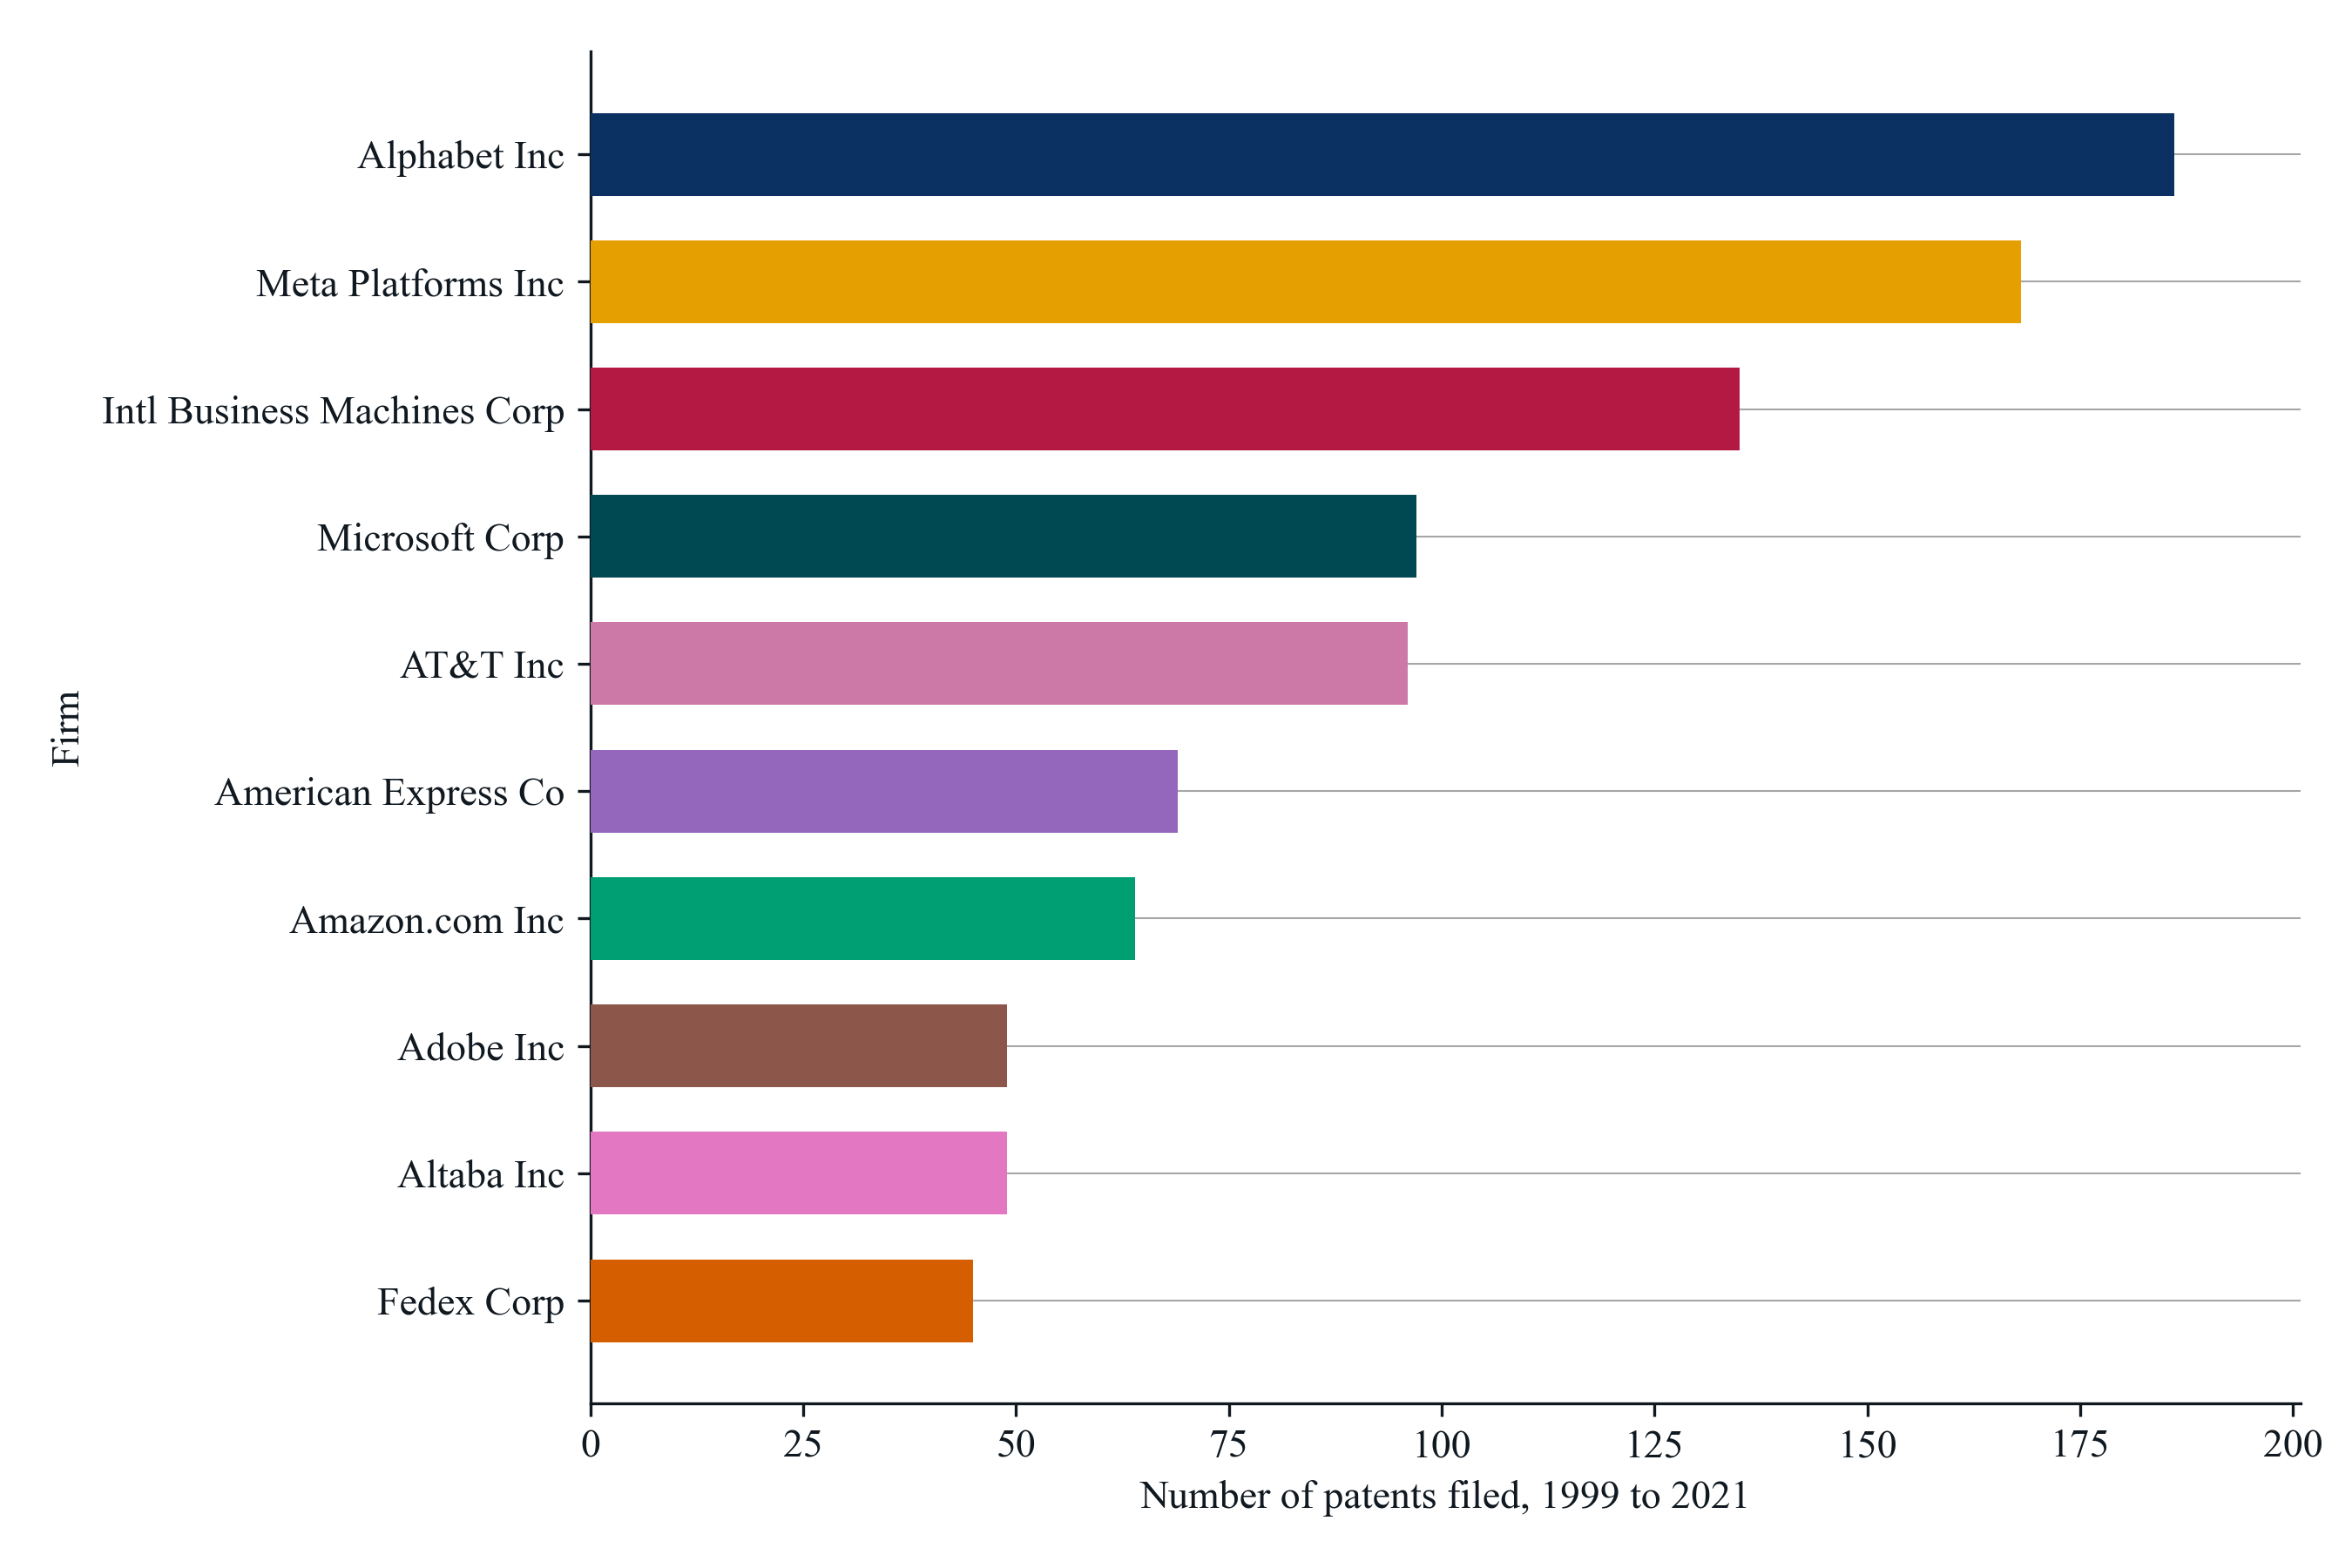

*Notes*: Each bar is the number of KPSS patents filed in 1999 to 2021 by the firm that carry CPC code G06Q 30/0269, "based on user profile or attribute", a subgroup of G06Q 30/0251, targeted advertisements, called advertising targeted by user profile here; the ten sample firms with the most, the largest at the top. The code appears on 1,430 patents of 78 sample firms, and the ten firms shown hold 67.0% of them. Every one of the 21 firms that is among the ten leaders of at least one code has a color of its own, the same in all figures of this notebook, assigned in order of the firm's total privacy patents. A patent that carries two of the listed codes counts under each. A privacy patent is a KPSS patent filed by a sample firm in 1999 to 2021 that carries at least one of the 5 CPC codes of the project's privacy code list (an exact match of the full code; a listed parent code does not pull in unlisted child codes). Firm names are Compustat names in title case. The sample firms are the 1,058 firms of the all-years T3 sample (every firm with a 10-K in the sample, fiscal 1999 to 2025), linked to their KPSS patents in T4.1.1.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list in privacy_cpc/privacy_cpc_codes_MM_102926.xlsx; sample firms from the 10-K sample of T3 (SEC EDGAR); authors' calculations.

Saved PNG, SVG, and PDF: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/output/T4.2.6/fig_1_ten_firms_advertising_targeted_by_user_profile


In [11]:
figure_name = "fig_1_ten_firms_advertising_targeted_by_user_profile"
code_display = "G06Q 30/0269"
code_title, code_sentence, code_place = CODE_NAMES[code_display]
figure_title = f"Figure 1. Ten Firms With the Most Patents on {code_title}, {PERIOD_WORDS}"
leaders = table_2_long.loc[table_2_long["cpc_display"].eq(code_display)].sort_values(["n_patents", "conm"], ascending=[True, False]).reset_index(drop=True)
firm_names = leaders["conm"].map(title_case_name)
bar_colors = [FIRM_COLORS[gvkey] for gvkey in leaders["gvkey"]]
code_total = int(by_firm_code[code_display].sum())
code_firms = int(firms_per_code[code_display])
code_definition = privacy_codes.set_index("cpc_display").loc[code_display, "definition"]

figure, axis = plt.subplots()
figure.subplots_adjust(left=0.30, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.14)
axis.barh(firm_names, leaders["n_patents"], color=bar_colors, height=0.65, zorder=3)
axis.set_xlabel(f"Number of patents filed, {PERIOD_WORDS}")
axis.set_ylabel("Firm")
axis.set_xlim(0, leaders["n_patents"].max() * 1.08)
axis.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
axis.spines[["top", "right"]].set_visible(False)

figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
bottom_shift = (margin_pixels - axis.xaxis.label.get_window_extent(renderer).y0) / figure.bbox.height
figure.subplots_adjust(left=figure.subplotpars.left + left_shift, bottom=figure.subplotpars.bottom + bottom_shift)
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

figure_notes = (f"Each bar is the number of KPSS patents filed in {PERIOD_WORDS} by the firm that carry CPC code {code_display}, \"{code_definition}\", {code_place}, "
                f"called {code_sentence} here; the ten sample firms with the most, the largest at the top. The code appears on {code_total:,} patents of {code_firms} sample firms, "
                f"and the ten firms shown hold {leaders['share_of_code'].sum():.1%} of them. {COLOR_WORDS}. "
                f"A patent that carries two of the listed codes counts under each. {PRIVACY_WORDS}. Firm names are Compustat names in title case. The sample firms are {SAMPLE_WORDS}.")
display(Markdown(f"**{figure_title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {figure_notes}\n\n*Source*: {SOURCE}"))
print(f"Saved PNG, SVG, and PDF: {OUTPUT_FOLDER / figure_name}")


## Step 12. Figure 2: the ten firms with the most patents on advertising targeted by user history

Horizontal bars, the firm with the most patents carrying G06Q 30/0255 at the top, each bar in the firm's shared color. The firm names are the tick labels, so no legend is drawn.

**Figure 2. Ten Firms With the Most Patents on Advertising Targeted by User History, 1999 to 2021**

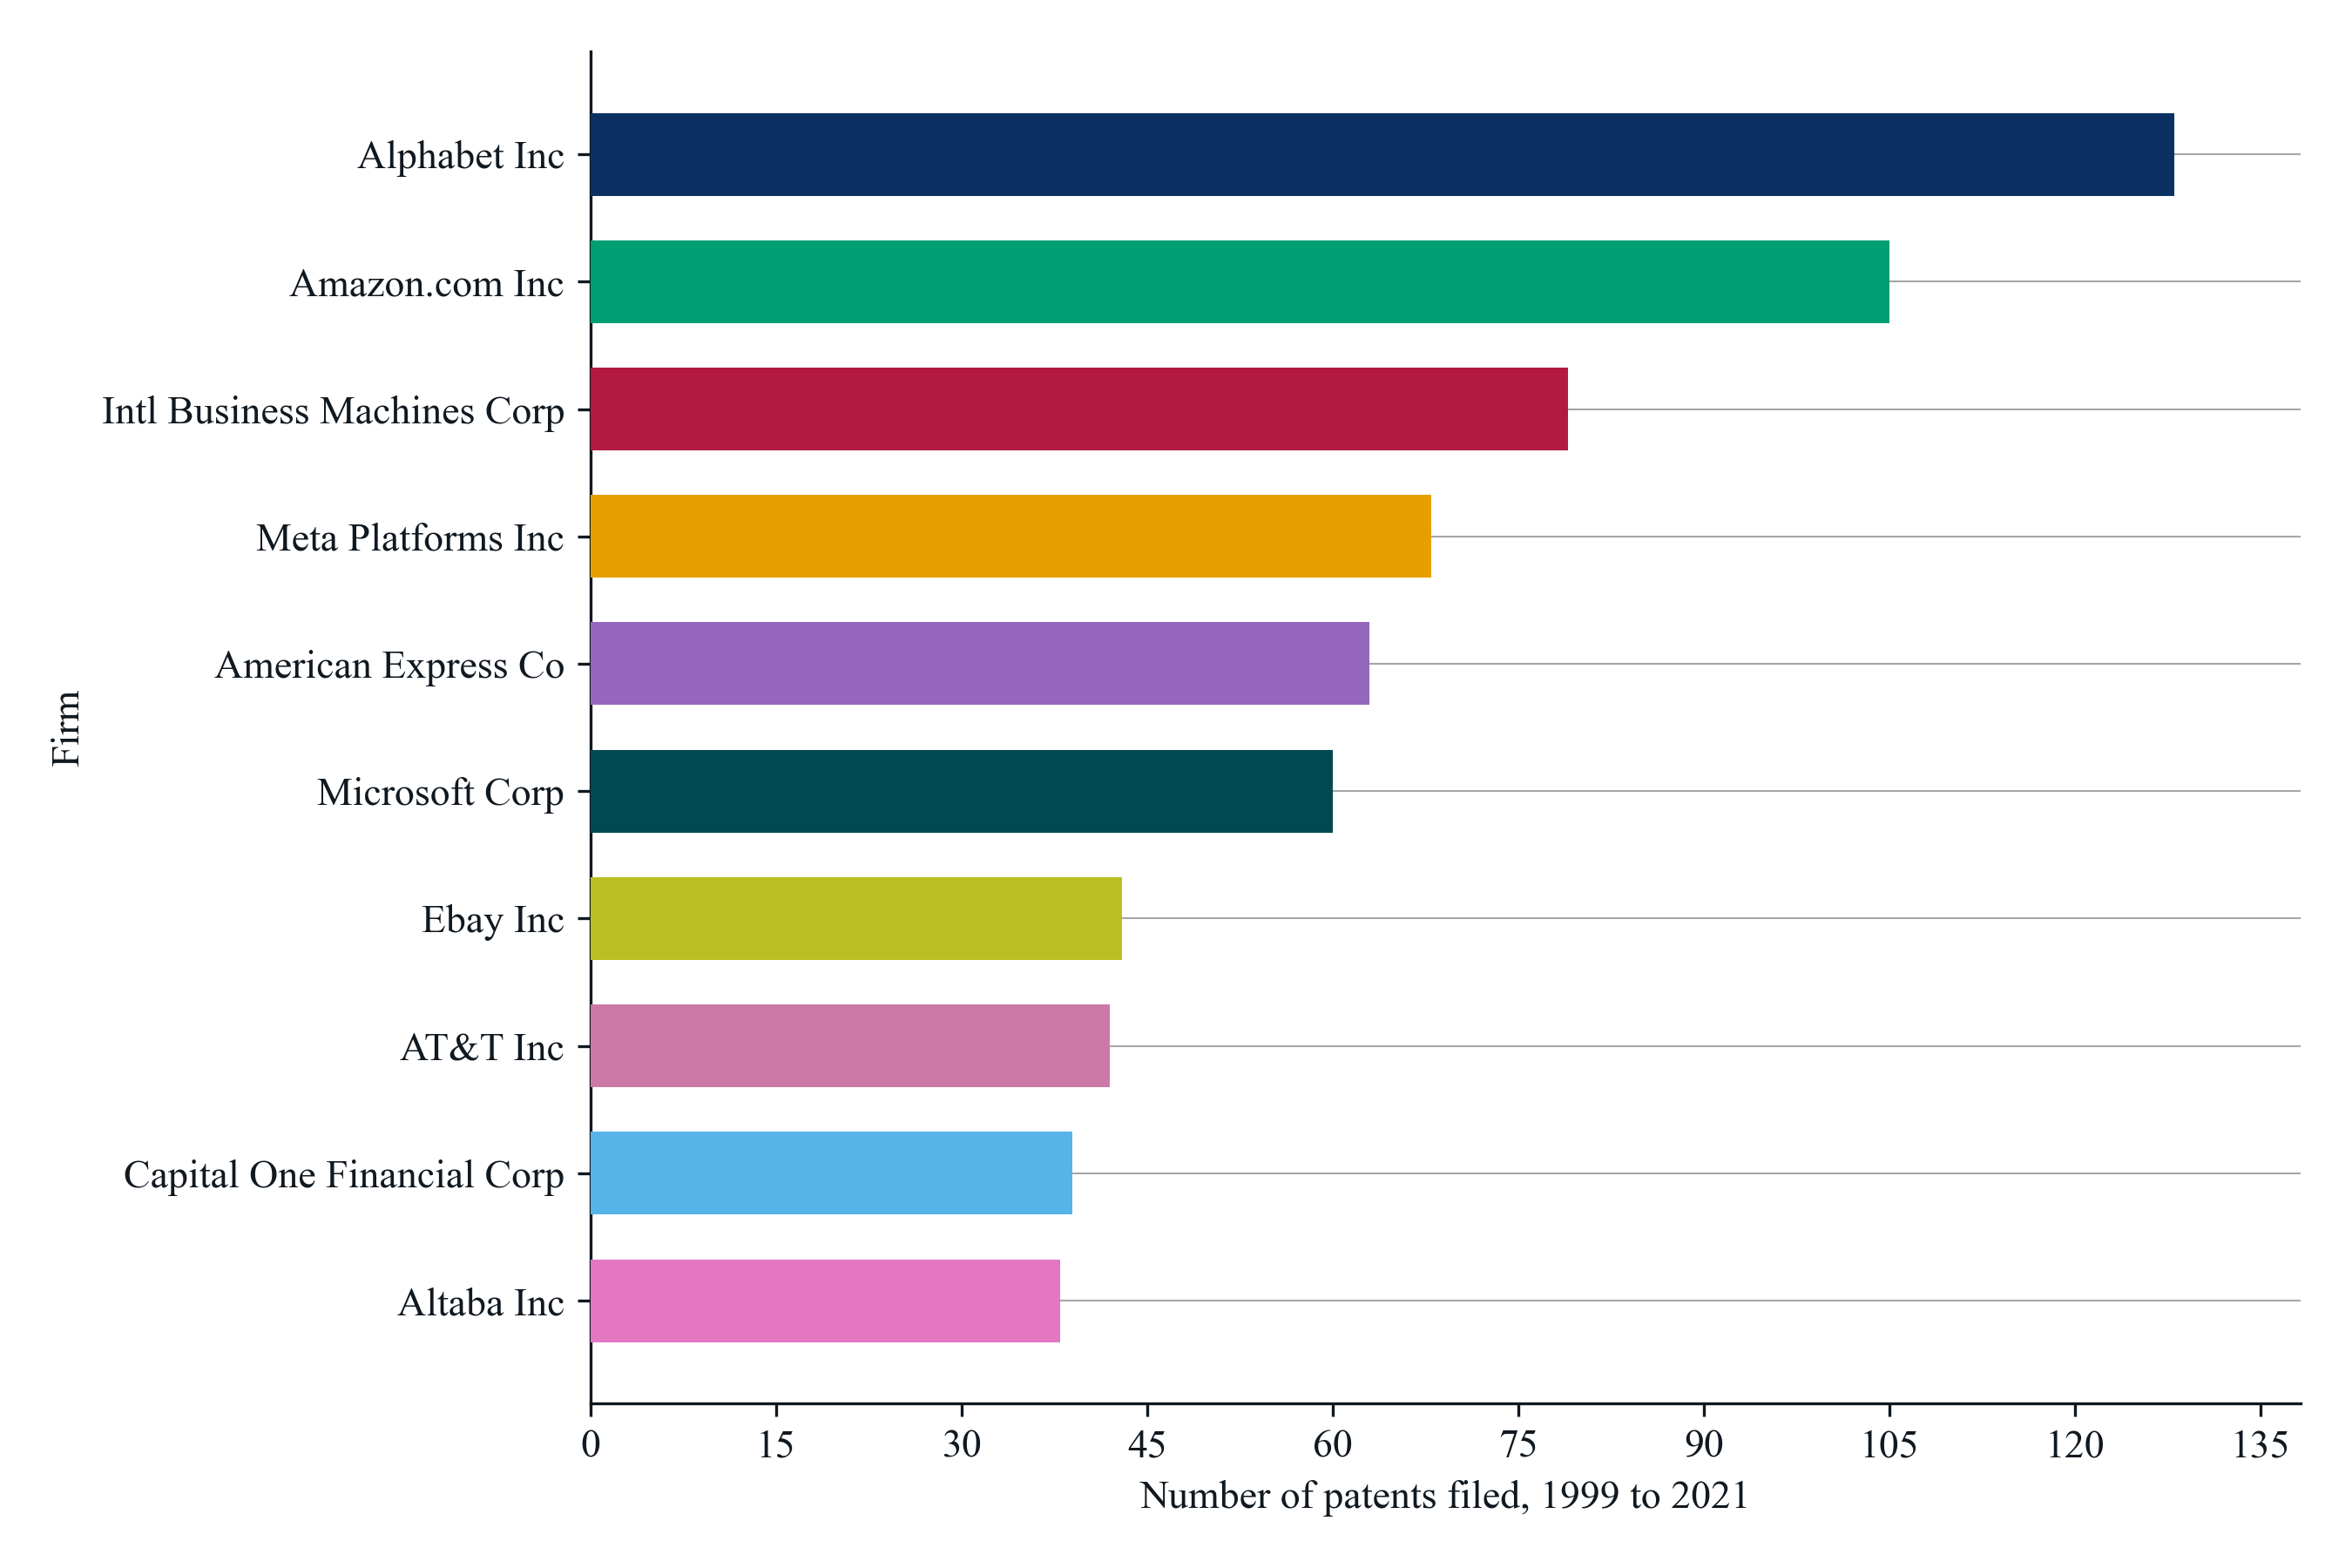

*Notes*: Each bar is the number of KPSS patents filed in 1999 to 2021 by the firm that carry CPC code G06Q 30/0255, "based on user history", a subgroup of G06Q 30/0251, targeted advertisements, called advertising targeted by user history here; the ten sample firms with the most, the largest at the top. The code appears on 1,011 patents of 69 sample firms, and the ten firms shown hold 65.8% of them. Every one of the 21 firms that is among the ten leaders of at least one code has a color of its own, the same in all figures of this notebook, assigned in order of the firm's total privacy patents. A patent that carries two of the listed codes counts under each. A privacy patent is a KPSS patent filed by a sample firm in 1999 to 2021 that carries at least one of the 5 CPC codes of the project's privacy code list (an exact match of the full code; a listed parent code does not pull in unlisted child codes). Firm names are Compustat names in title case. The sample firms are the 1,058 firms of the all-years T3 sample (every firm with a 10-K in the sample, fiscal 1999 to 2025), linked to their KPSS patents in T4.1.1.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list in privacy_cpc/privacy_cpc_codes_MM_102926.xlsx; sample firms from the 10-K sample of T3 (SEC EDGAR); authors' calculations.

Saved PNG, SVG, and PDF: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/output/T4.2.6/fig_2_ten_firms_advertising_targeted_by_user_history


In [12]:
figure_name = "fig_2_ten_firms_advertising_targeted_by_user_history"
code_display = "G06Q 30/0255"
code_title, code_sentence, code_place = CODE_NAMES[code_display]
figure_title = f"Figure 2. Ten Firms With the Most Patents on {code_title}, {PERIOD_WORDS}"
leaders = table_2_long.loc[table_2_long["cpc_display"].eq(code_display)].sort_values(["n_patents", "conm"], ascending=[True, False]).reset_index(drop=True)
firm_names = leaders["conm"].map(title_case_name)
bar_colors = [FIRM_COLORS[gvkey] for gvkey in leaders["gvkey"]]
code_total = int(by_firm_code[code_display].sum())
code_firms = int(firms_per_code[code_display])
code_definition = privacy_codes.set_index("cpc_display").loc[code_display, "definition"]

figure, axis = plt.subplots()
figure.subplots_adjust(left=0.30, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.14)
axis.barh(firm_names, leaders["n_patents"], color=bar_colors, height=0.65, zorder=3)
axis.set_xlabel(f"Number of patents filed, {PERIOD_WORDS}")
axis.set_ylabel("Firm")
axis.set_xlim(0, leaders["n_patents"].max() * 1.08)
axis.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
axis.spines[["top", "right"]].set_visible(False)

figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
bottom_shift = (margin_pixels - axis.xaxis.label.get_window_extent(renderer).y0) / figure.bbox.height
figure.subplots_adjust(left=figure.subplotpars.left + left_shift, bottom=figure.subplotpars.bottom + bottom_shift)
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

figure_notes = (f"Each bar is the number of KPSS patents filed in {PERIOD_WORDS} by the firm that carry CPC code {code_display}, \"{code_definition}\", {code_place}, "
                f"called {code_sentence} here; the ten sample firms with the most, the largest at the top. The code appears on {code_total:,} patents of {code_firms} sample firms, "
                f"and the ten firms shown hold {leaders['share_of_code'].sum():.1%} of them. {COLOR_WORDS}. "
                f"A patent that carries two of the listed codes counts under each. {PRIVACY_WORDS}. Firm names are Compustat names in title case. The sample firms are {SAMPLE_WORDS}.")
display(Markdown(f"**{figure_title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {figure_notes}\n\n*Source*: {SOURCE}"))
print(f"Saved PNG, SVG, and PDF: {OUTPUT_FOLDER / figure_name}")


## Step 13. Figure 3: the ten firms with the most patents on anonymisation of personal data

Horizontal bars, the firm with the most patents carrying G06F 21/6254 at the top, each bar in the firm's shared color. The firm names are the tick labels, so no legend is drawn.

**Figure 3. Ten Firms With the Most Patents on Anonymisation of Personal Data, 1999 to 2021**

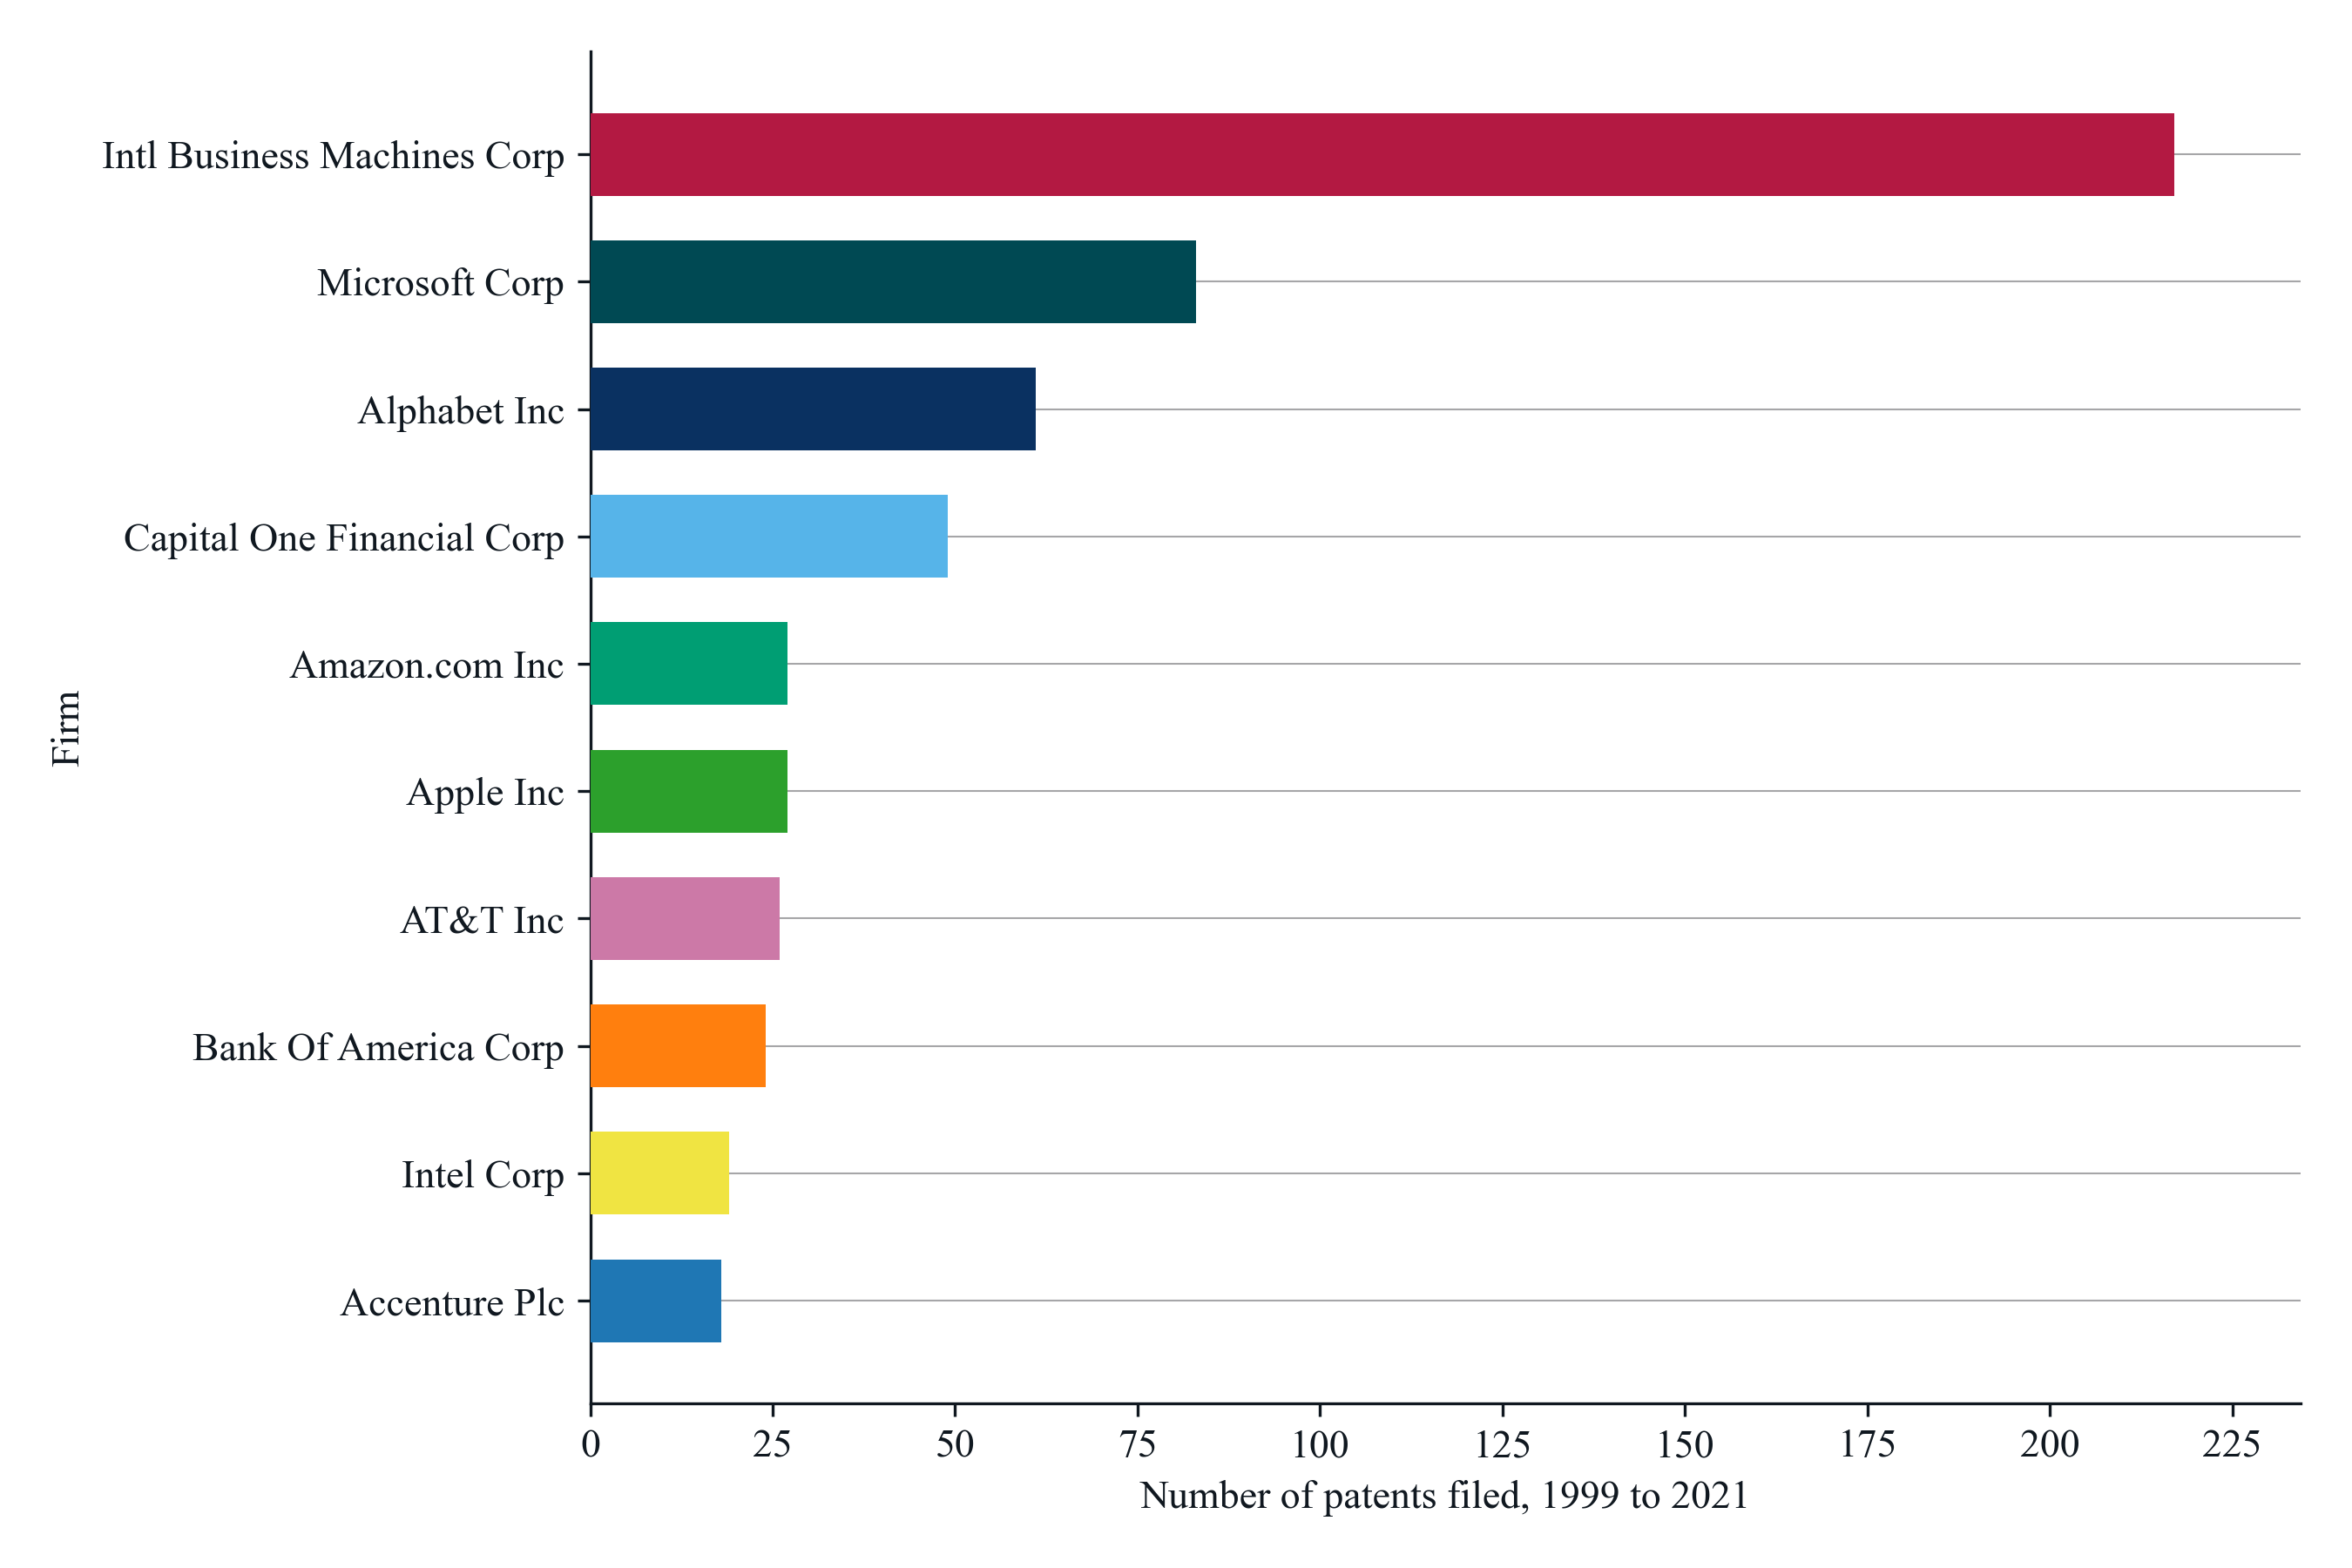

*Notes*: Each bar is the number of KPSS patents filed in 1999 to 2021 by the firm that carry CPC code G06F 21/6254, "by anonymising data, e.g. decorrelating personal data from the owner's identification", a subgroup of G06F 21/62, protecting access to data via a platform, called anonymisation of personal data here; the ten sample firms with the most, the largest at the top. The code appears on 819 patents of 75 sample firms, and the ten firms shown hold 67.3% of them. Every one of the 21 firms that is among the ten leaders of at least one code has a color of its own, the same in all figures of this notebook, assigned in order of the firm's total privacy patents. A patent that carries two of the listed codes counts under each. A privacy patent is a KPSS patent filed by a sample firm in 1999 to 2021 that carries at least one of the 5 CPC codes of the project's privacy code list (an exact match of the full code; a listed parent code does not pull in unlisted child codes). Firm names are Compustat names in title case. The sample firms are the 1,058 firms of the all-years T3 sample (every firm with a 10-K in the sample, fiscal 1999 to 2025), linked to their KPSS patents in T4.1.1.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list in privacy_cpc/privacy_cpc_codes_MM_102926.xlsx; sample firms from the 10-K sample of T3 (SEC EDGAR); authors' calculations.

Saved PNG, SVG, and PDF: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/output/T4.2.6/fig_3_ten_firms_anonymisation_of_personal_data


In [13]:
figure_name = "fig_3_ten_firms_anonymisation_of_personal_data"
code_display = "G06F 21/6254"
code_title, code_sentence, code_place = CODE_NAMES[code_display]
figure_title = f"Figure 3. Ten Firms With the Most Patents on {code_title}, {PERIOD_WORDS}"
leaders = table_2_long.loc[table_2_long["cpc_display"].eq(code_display)].sort_values(["n_patents", "conm"], ascending=[True, False]).reset_index(drop=True)
firm_names = leaders["conm"].map(title_case_name)
bar_colors = [FIRM_COLORS[gvkey] for gvkey in leaders["gvkey"]]
code_total = int(by_firm_code[code_display].sum())
code_firms = int(firms_per_code[code_display])
code_definition = privacy_codes.set_index("cpc_display").loc[code_display, "definition"]

figure, axis = plt.subplots()
figure.subplots_adjust(left=0.30, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.14)
axis.barh(firm_names, leaders["n_patents"], color=bar_colors, height=0.65, zorder=3)
axis.set_xlabel(f"Number of patents filed, {PERIOD_WORDS}")
axis.set_ylabel("Firm")
axis.set_xlim(0, leaders["n_patents"].max() * 1.08)
axis.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
axis.spines[["top", "right"]].set_visible(False)

figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
bottom_shift = (margin_pixels - axis.xaxis.label.get_window_extent(renderer).y0) / figure.bbox.height
figure.subplots_adjust(left=figure.subplotpars.left + left_shift, bottom=figure.subplotpars.bottom + bottom_shift)
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

figure_notes = (f"Each bar is the number of KPSS patents filed in {PERIOD_WORDS} by the firm that carry CPC code {code_display}, \"{code_definition}\", {code_place}, "
                f"called {code_sentence} here; the ten sample firms with the most, the largest at the top. The code appears on {code_total:,} patents of {code_firms} sample firms, "
                f"and the ten firms shown hold {leaders['share_of_code'].sum():.1%} of them. {COLOR_WORDS}. "
                f"A patent that carries two of the listed codes counts under each. {PRIVACY_WORDS}. Firm names are Compustat names in title case. The sample firms are {SAMPLE_WORDS}.")
display(Markdown(f"**{figure_title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {figure_notes}\n\n*Source*: {SOURCE}"))
print(f"Saved PNG, SVG, and PDF: {OUTPUT_FOLDER / figure_name}")


## Step 14. Figure 4: the ten firms with the most patents on tracking of user activity in network services

Horizontal bars, the firm with the most patents carrying H04L 67/535 at the top, each bar in the firm's shared color. The firm names are the tick labels, so no legend is drawn.

**Figure 4. Ten Firms With the Most Patents on Tracking of User Activity in Network Services, 1999 to 2021**

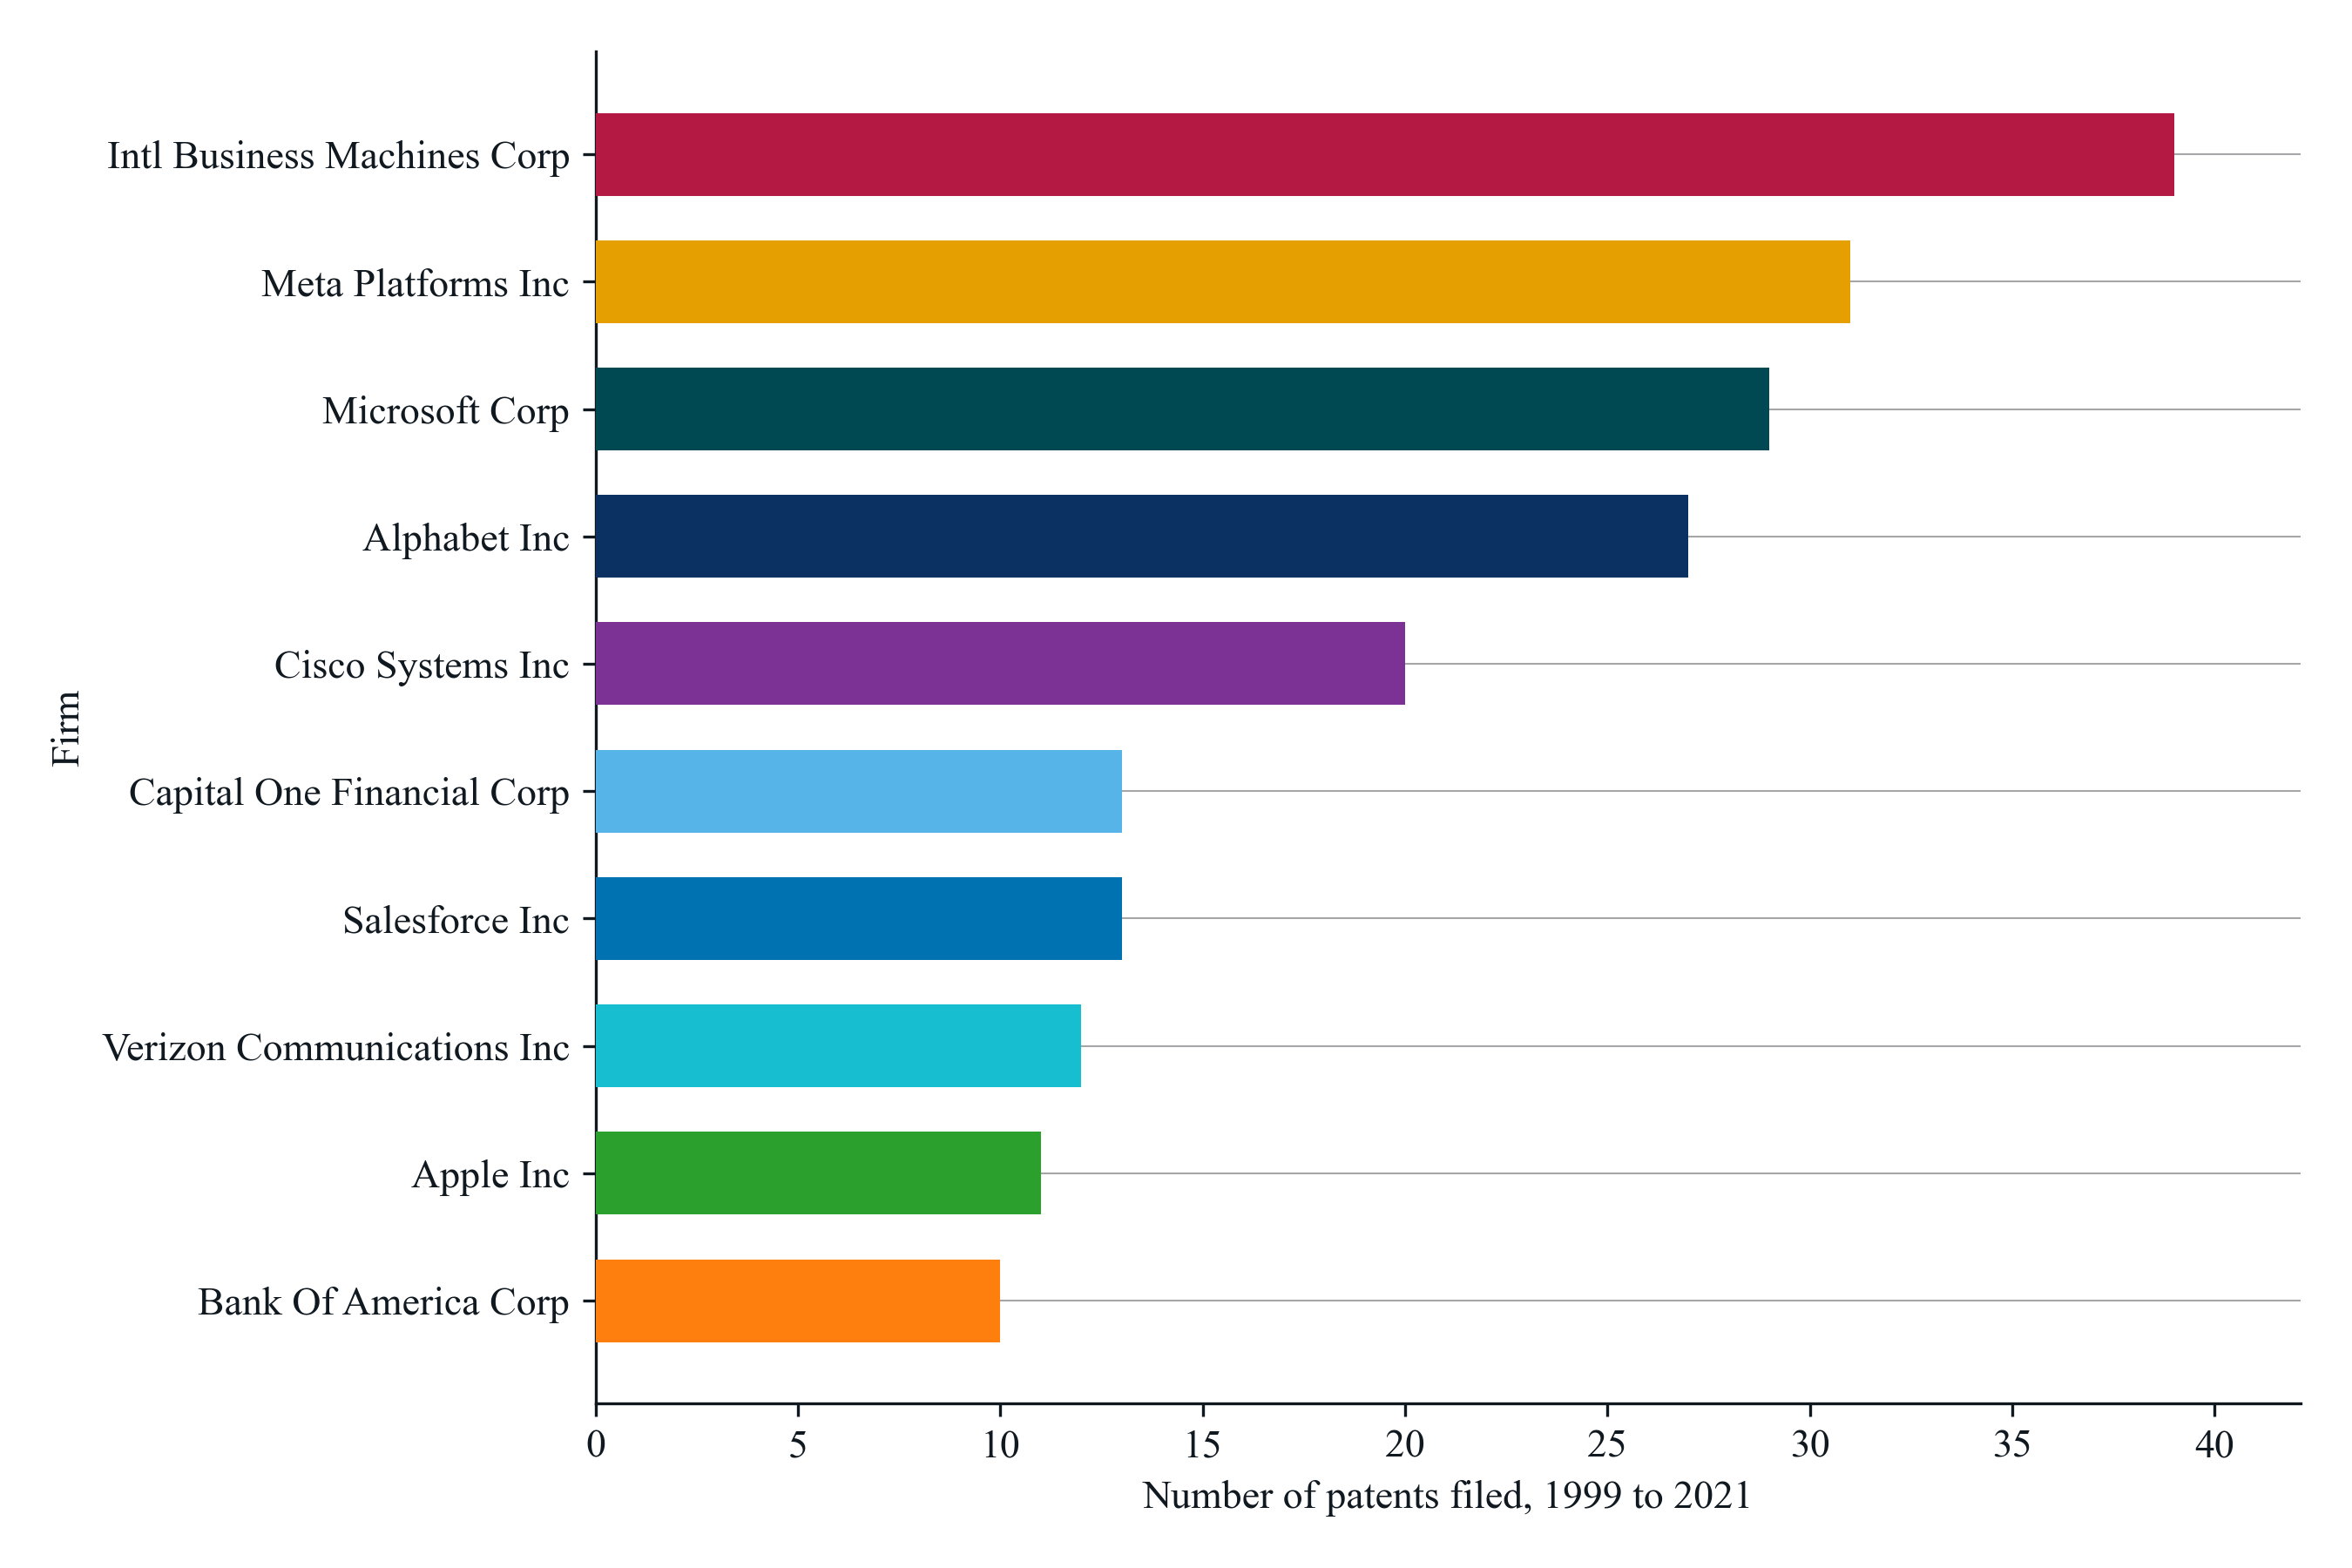

*Notes*: Each bar is the number of KPSS patents filed in 1999 to 2021 by the firm that carry CPC code H04L 67/535, "Tracking the activity of the user (network monitoring arrangements H04L 43/00; recording of computer activity G06F 11/34)", a subgroup of H04L 67/50, network services, called tracking of user activity in network services here; the ten sample firms with the most, the largest at the top. The code appears on 354 patents of 60 sample firms, and the ten firms shown hold 57.9% of them. Every one of the 21 firms that is among the ten leaders of at least one code has a color of its own, the same in all figures of this notebook, assigned in order of the firm's total privacy patents. A patent that carries two of the listed codes counts under each. A privacy patent is a KPSS patent filed by a sample firm in 1999 to 2021 that carries at least one of the 5 CPC codes of the project's privacy code list (an exact match of the full code; a listed parent code does not pull in unlisted child codes). Firm names are Compustat names in title case. The sample firms are the 1,058 firms of the all-years T3 sample (every firm with a 10-K in the sample, fiscal 1999 to 2025), linked to their KPSS patents in T4.1.1.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list in privacy_cpc/privacy_cpc_codes_MM_102926.xlsx; sample firms from the 10-K sample of T3 (SEC EDGAR); authors' calculations.

Saved PNG, SVG, and PDF: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/output/T4.2.6/fig_4_ten_firms_tracking_of_user_activity_in_network_services


In [14]:
figure_name = "fig_4_ten_firms_tracking_of_user_activity_in_network_services"
code_display = "H04L 67/535"
code_title, code_sentence, code_place = CODE_NAMES[code_display]
figure_title = f"Figure 4. Ten Firms With the Most Patents on {code_title}, {PERIOD_WORDS}"
leaders = table_2_long.loc[table_2_long["cpc_display"].eq(code_display)].sort_values(["n_patents", "conm"], ascending=[True, False]).reset_index(drop=True)
firm_names = leaders["conm"].map(title_case_name)
bar_colors = [FIRM_COLORS[gvkey] for gvkey in leaders["gvkey"]]
code_total = int(by_firm_code[code_display].sum())
code_firms = int(firms_per_code[code_display])
code_definition = privacy_codes.set_index("cpc_display").loc[code_display, "definition"]

figure, axis = plt.subplots()
figure.subplots_adjust(left=0.30, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.14)
axis.barh(firm_names, leaders["n_patents"], color=bar_colors, height=0.65, zorder=3)
axis.set_xlabel(f"Number of patents filed, {PERIOD_WORDS}")
axis.set_ylabel("Firm")
axis.set_xlim(0, leaders["n_patents"].max() * 1.08)
axis.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
axis.spines[["top", "right"]].set_visible(False)

figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
bottom_shift = (margin_pixels - axis.xaxis.label.get_window_extent(renderer).y0) / figure.bbox.height
figure.subplots_adjust(left=figure.subplotpars.left + left_shift, bottom=figure.subplotpars.bottom + bottom_shift)
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

figure_notes = (f"Each bar is the number of KPSS patents filed in {PERIOD_WORDS} by the firm that carry CPC code {code_display}, \"{code_definition}\", {code_place}, "
                f"called {code_sentence} here; the ten sample firms with the most, the largest at the top. The code appears on {code_total:,} patents of {code_firms} sample firms, "
                f"and the ten firms shown hold {leaders['share_of_code'].sum():.1%} of them. {COLOR_WORDS}. "
                f"A patent that carries two of the listed codes counts under each. {PRIVACY_WORDS}. Firm names are Compustat names in title case. The sample firms are {SAMPLE_WORDS}.")
display(Markdown(f"**{figure_title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {figure_notes}\n\n*Source*: {SOURCE}"))
print(f"Saved PNG, SVG, and PDF: {OUTPUT_FOLDER / figure_name}")


## Step 15. Figure 5: the ten firms with the most patents on monitoring of user actions on computers

Horizontal bars, the firm with the most patents carrying G06F 11/3438 at the top, each bar in the firm's shared color. The firm names are the tick labels, so no legend is drawn.

**Figure 5. Ten Firms With the Most Patents on Monitoring of User Actions on Computers, 1999 to 2021**

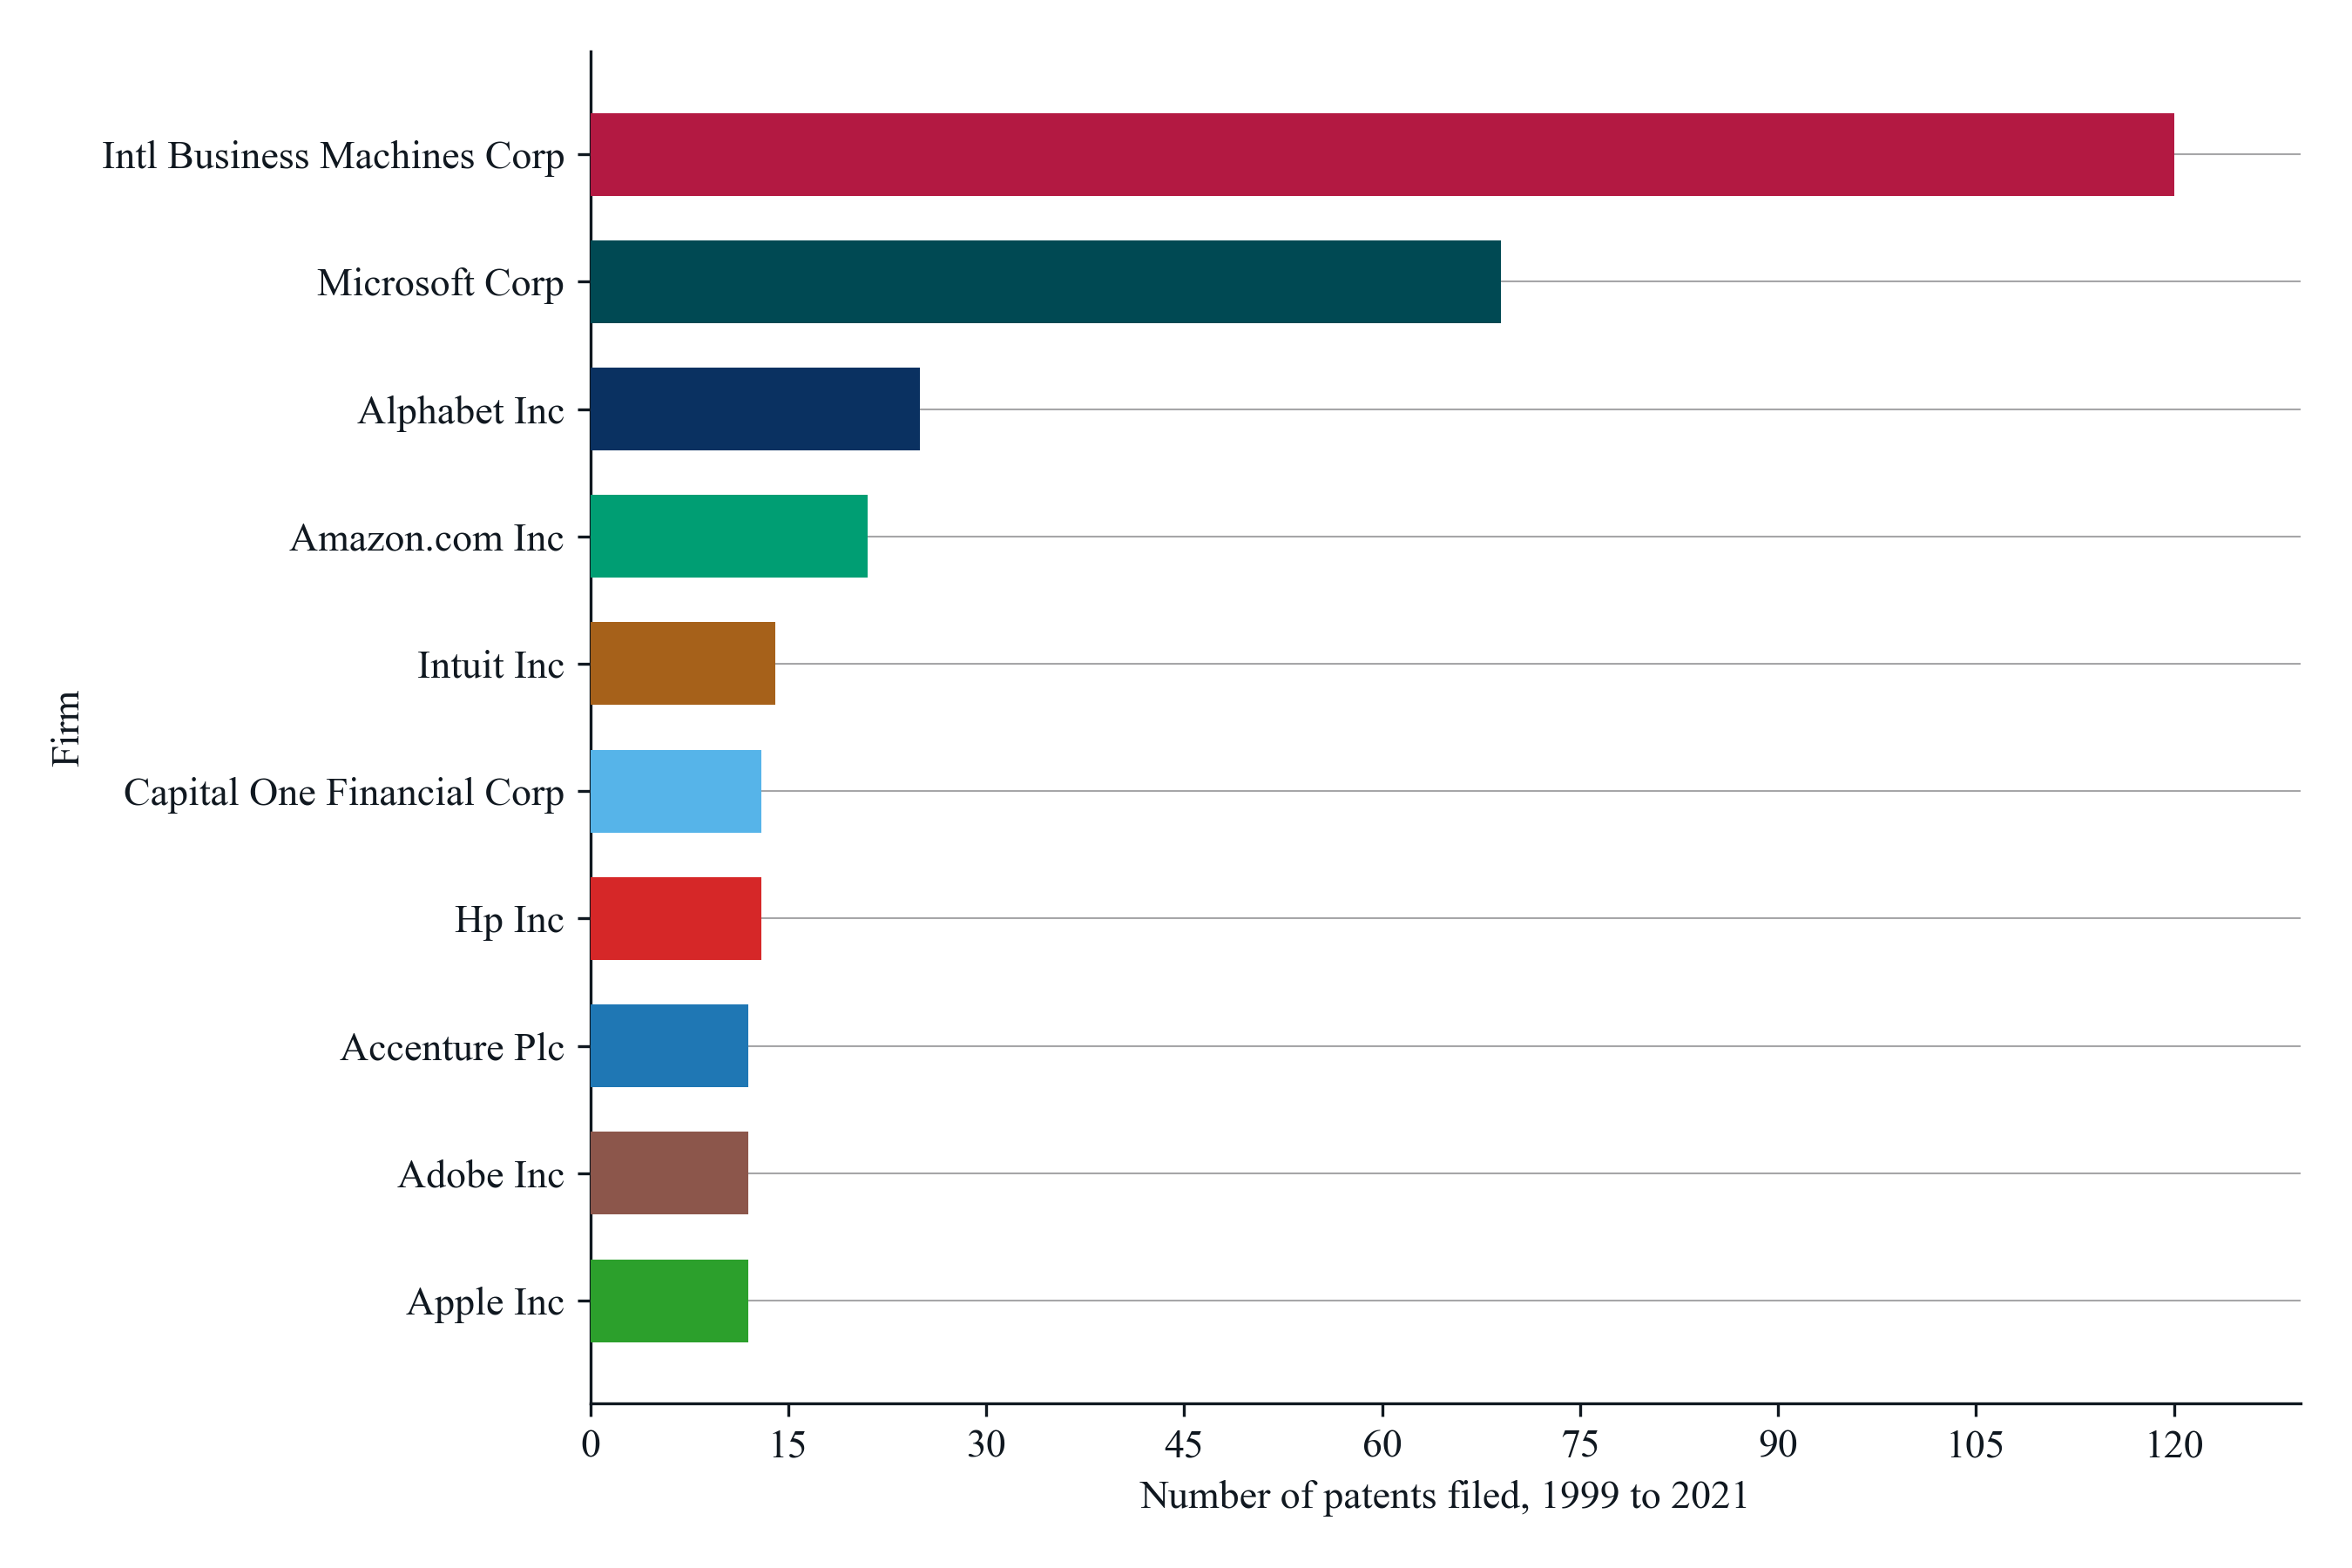

*Notes*: Each bar is the number of KPSS patents filed in 1999 to 2021 by the firm that carry CPC code G06F 11/3438, "monitoring of user actions (tracking the activity of the user H04L 67/535)", a subgroup of G06F 11/34, recording or statistical evaluation of computer activity, called monitoring of user actions on computers here; the ten sample firms with the most, the largest at the top. The code appears on 457 patents of 59 sample firms, and the ten firms shown hold 68.1% of them. Every one of the 21 firms that is among the ten leaders of at least one code has a color of its own, the same in all figures of this notebook, assigned in order of the firm's total privacy patents. A patent that carries two of the listed codes counts under each. A privacy patent is a KPSS patent filed by a sample firm in 1999 to 2021 that carries at least one of the 5 CPC codes of the project's privacy code list (an exact match of the full code; a listed parent code does not pull in unlisted child codes). Firm names are Compustat names in title case. The sample firms are the 1,058 firms of the all-years T3 sample (every firm with a 10-K in the sample, fiscal 1999 to 2025), linked to their KPSS patents in T4.1.1.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list in privacy_cpc/privacy_cpc_codes_MM_102926.xlsx; sample firms from the 10-K sample of T3 (SEC EDGAR); authors' calculations.

Saved PNG, SVG, and PDF: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/output/T4.2.6/fig_5_ten_firms_monitoring_of_user_actions_on_computers


In [15]:
figure_name = "fig_5_ten_firms_monitoring_of_user_actions_on_computers"
code_display = "G06F 11/3438"
code_title, code_sentence, code_place = CODE_NAMES[code_display]
figure_title = f"Figure 5. Ten Firms With the Most Patents on {code_title}, {PERIOD_WORDS}"
leaders = table_2_long.loc[table_2_long["cpc_display"].eq(code_display)].sort_values(["n_patents", "conm"], ascending=[True, False]).reset_index(drop=True)
firm_names = leaders["conm"].map(title_case_name)
bar_colors = [FIRM_COLORS[gvkey] for gvkey in leaders["gvkey"]]
code_total = int(by_firm_code[code_display].sum())
code_firms = int(firms_per_code[code_display])
code_definition = privacy_codes.set_index("cpc_display").loc[code_display, "definition"]

figure, axis = plt.subplots()
figure.subplots_adjust(left=0.30, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.14)
axis.barh(firm_names, leaders["n_patents"], color=bar_colors, height=0.65, zorder=3)
axis.set_xlabel(f"Number of patents filed, {PERIOD_WORDS}")
axis.set_ylabel("Firm")
axis.set_xlim(0, leaders["n_patents"].max() * 1.08)
axis.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
axis.spines[["top", "right"]].set_visible(False)

figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
bottom_shift = (margin_pixels - axis.xaxis.label.get_window_extent(renderer).y0) / figure.bbox.height
figure.subplots_adjust(left=figure.subplotpars.left + left_shift, bottom=figure.subplotpars.bottom + bottom_shift)
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

figure_notes = (f"Each bar is the number of KPSS patents filed in {PERIOD_WORDS} by the firm that carry CPC code {code_display}, \"{code_definition}\", {code_place}, "
                f"called {code_sentence} here; the ten sample firms with the most, the largest at the top. The code appears on {code_total:,} patents of {code_firms} sample firms, "
                f"and the ten firms shown hold {leaders['share_of_code'].sum():.1%} of them. {COLOR_WORDS}. "
                f"A patent that carries two of the listed codes counts under each. {PRIVACY_WORDS}. Firm names are Compustat names in title case. The sample firms are {SAMPLE_WORDS}.")
display(Markdown(f"**{figure_title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {figure_notes}\n\n*Source*: {SOURCE}"))
print(f"Saved PNG, SVG, and PDF: {OUTPUT_FOLDER / figure_name}")


## Step 16. Figure 6: the five codes side by side

The five single-code figures on one canvas, two rows of three panels with the sixth position empty, each panel titled "Patents on <name> (<code>), 1999 to 2021". Each panel keeps its own horizontal scale, the firm colors of Step 9, and the firm names as tick labels. This figure departs from the one-panel rule of the Figure Style Guide on purpose, so that a reader can compare the five codes at a glance.

**Figure 6. Ten Firms With the Most Patents on Each Privacy Code, 1999 to 2021**

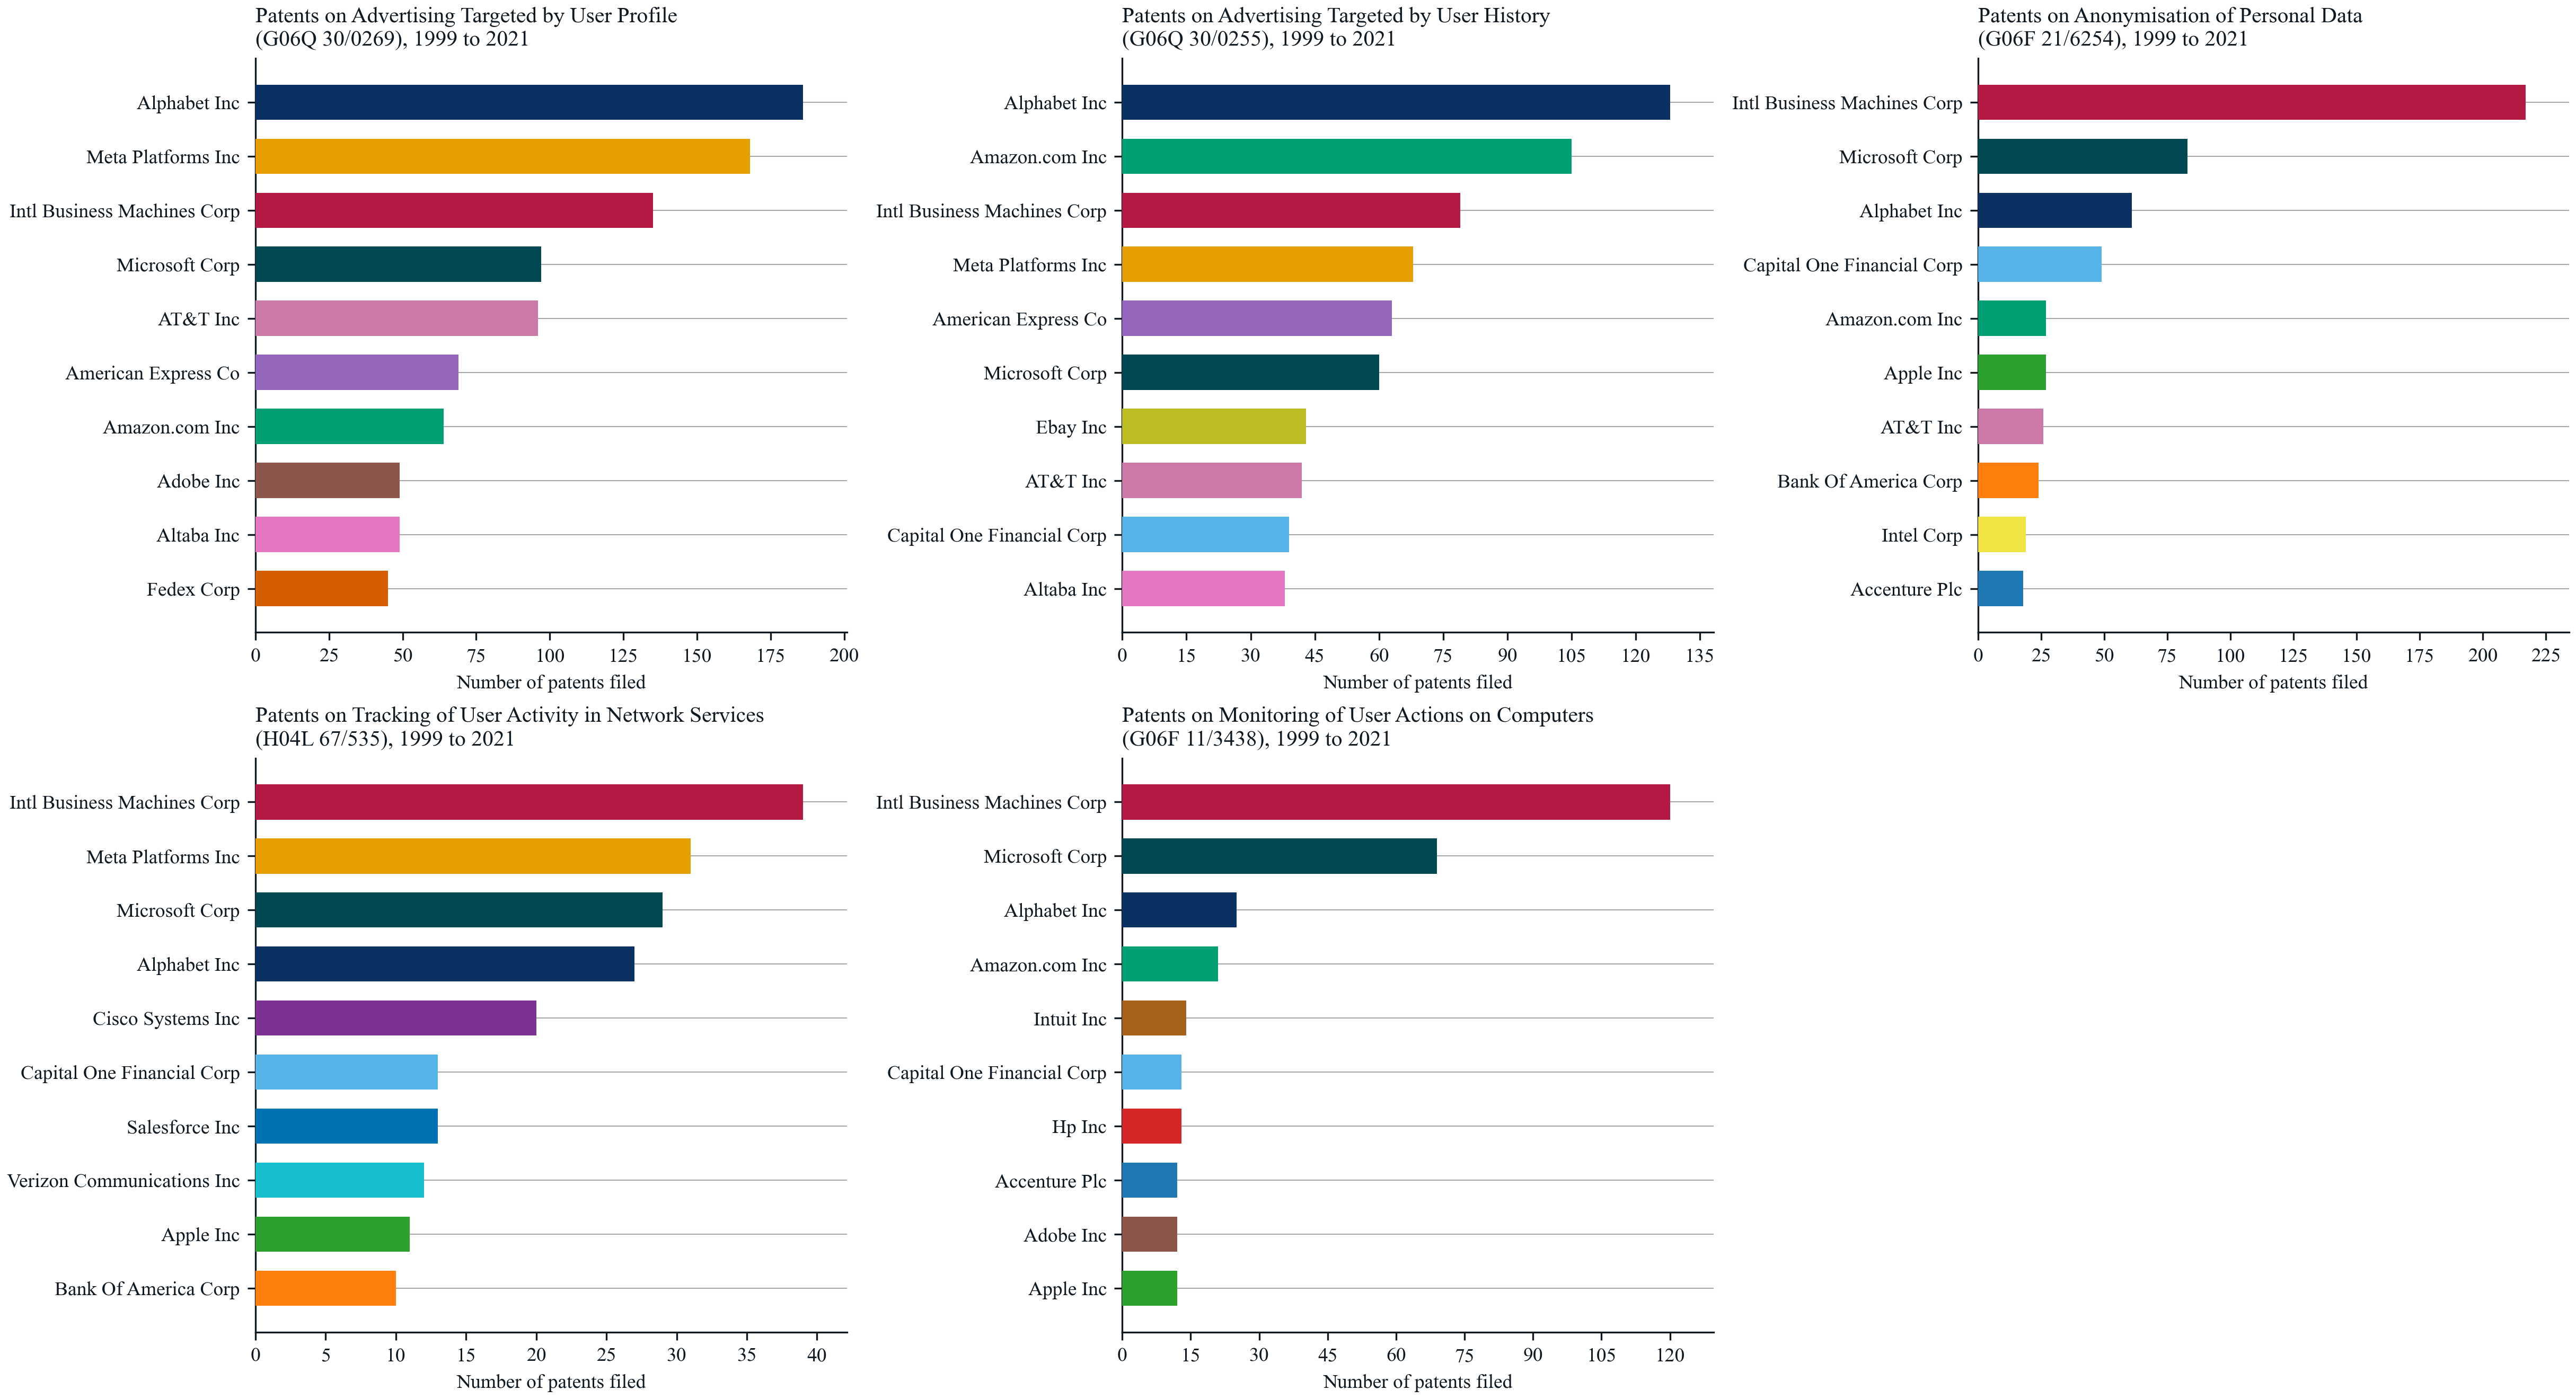

*Notes*: Each panel is one of the five codes of the privacy code list and shows the ten sample firms with the most KPSS patents filed in 1999 to 2021 that carry the code, the largest at the top, with the number of such patents on the horizontal axis; the scale differs across panels. The panel title gives the code's plain-language name and the code: Advertising Targeted by User Profile is G06Q 30/0269, "based on user profile or attribute"; Advertising Targeted by User History is G06Q 30/0255, "based on user history"; Anonymisation of Personal Data is G06F 21/6254, "by anonymising data, e.g. decorrelating personal data from the owner's identification"; Tracking of User Activity in Network Services is H04L 67/535, "Tracking the activity of the user (network monitoring arrangements H04L 43/00; recording of computer activity G06F 11/34)"; Monitoring of User Actions on Computers is G06F 11/3438, "monitoring of user actions (tracking the activity of the user H04L 67/535)". Every one of the 21 firms that is among the ten leaders of at least one code has a color of its own, the same in all figures of this notebook, assigned in order of the firm's total privacy patents, so the same firm has the same color in every panel. A patent that carries two of the listed codes counts under each. A privacy patent is a KPSS patent filed by a sample firm in 1999 to 2021 that carries at least one of the 5 CPC codes of the project's privacy code list (an exact match of the full code; a listed parent code does not pull in unlisted child codes). Firm names are Compustat names in title case. The sample firms are the 1,058 firms of the all-years T3 sample (every firm with a 10-K in the sample, fiscal 1999 to 2025), linked to their KPSS patents in T4.1.1.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list in privacy_cpc/privacy_cpc_codes_MM_102926.xlsx; sample firms from the 10-K sample of T3 (SEC EDGAR); authors' calculations.

Saved PNG, SVG, and PDF: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/output/T4.2.6/fig_6_ten_firms_per_code_five_panels


In [16]:
figure_name = "fig_6_ten_firms_per_code_five_panels"
figure_title = f"Figure 6. Ten Firms With the Most Patents on Each Privacy Code, {PERIOD_WORDS}"
PANEL_WIDTH = 5.4
PANEL_HEIGHT = 4.4
figure, axes = plt.subplots(2, 3, figsize=(3 * PANEL_WIDTH, 2 * PANEL_HEIGHT), constrained_layout=True)
axes = axes.ravel()
for axis, code_display in zip(axes, CODE_ORDER):
    code_title, code_sentence, code_place = CODE_NAMES[code_display]
    leaders = table_2_long.loc[table_2_long["cpc_display"].eq(code_display)].sort_values(["n_patents", "conm"], ascending=[True, False])
    axis.barh(leaders["conm"].map(title_case_name), leaders["n_patents"], color=[FIRM_COLORS[gvkey] for gvkey in leaders["gvkey"]], height=0.65, zorder=3)
    axis.set_title(f"Patents on {code_title}\n({code_display}), {PERIOD_WORDS}", fontsize=10, loc="left")
    axis.set_xlabel("Number of patents filed", fontsize=9)
    axis.tick_params(labelsize=9)
    axis.set_xlim(0, leaders["n_patents"].max() * 1.08)
    axis.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
    axis.spines[["top", "right"]].set_visible(False)
axes[-1].axis("off")
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

figure_notes = (f"Each panel is one of the five codes of the privacy code list and shows the ten sample firms with the most KPSS patents filed in {PERIOD_WORDS} that carry the code, the largest at the top, "
                f"with the number of such patents on the horizontal axis; the scale differs across panels. The panel title gives the code's plain-language name and the code: "
                + "; ".join(f"{CODE_NAMES[c][0]} is {c}, \"{privacy_codes.set_index('cpc_display').loc[c, 'definition']}\"" for c in CODE_ORDER)
                + f". {COLOR_WORDS}, so the same firm has the same color in every panel. A patent that carries two of the listed codes counts under each. "
                f"{PRIVACY_WORDS}. Firm names are Compustat names in title case. The sample firms are {SAMPLE_WORDS}.")
display(Markdown(f"**{figure_title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=1100))
display(Markdown(f"*Notes*: {figure_notes}\n\n*Source*: {SOURCE}"))
print(f"Saved PNG, SVG, and PDF: {OUTPUT_FOLDER / figure_name}")


## Step 17. Figure 7: the largest privacy patenters, each bar split by code

The 20 firms with the most privacy patents, the largest at the top, one stacked bar per firm. A bar's length is the firm's number of distinct privacy patents, as in Table 1. It is split into the patents that carry exactly one of the five codes, colored by that code, and the patents that carry two of the codes, in GREY, so that the segments add up to the firm's total and no patent is counted twice. The per-code counts that count such a patent under each code remain in Table 1. The legend names the codes and sits below the X-title.

**Figure 7. Privacy Patents of the 20 Sample Firms With the Most, Split by CPC Code, 1999 to 2021**

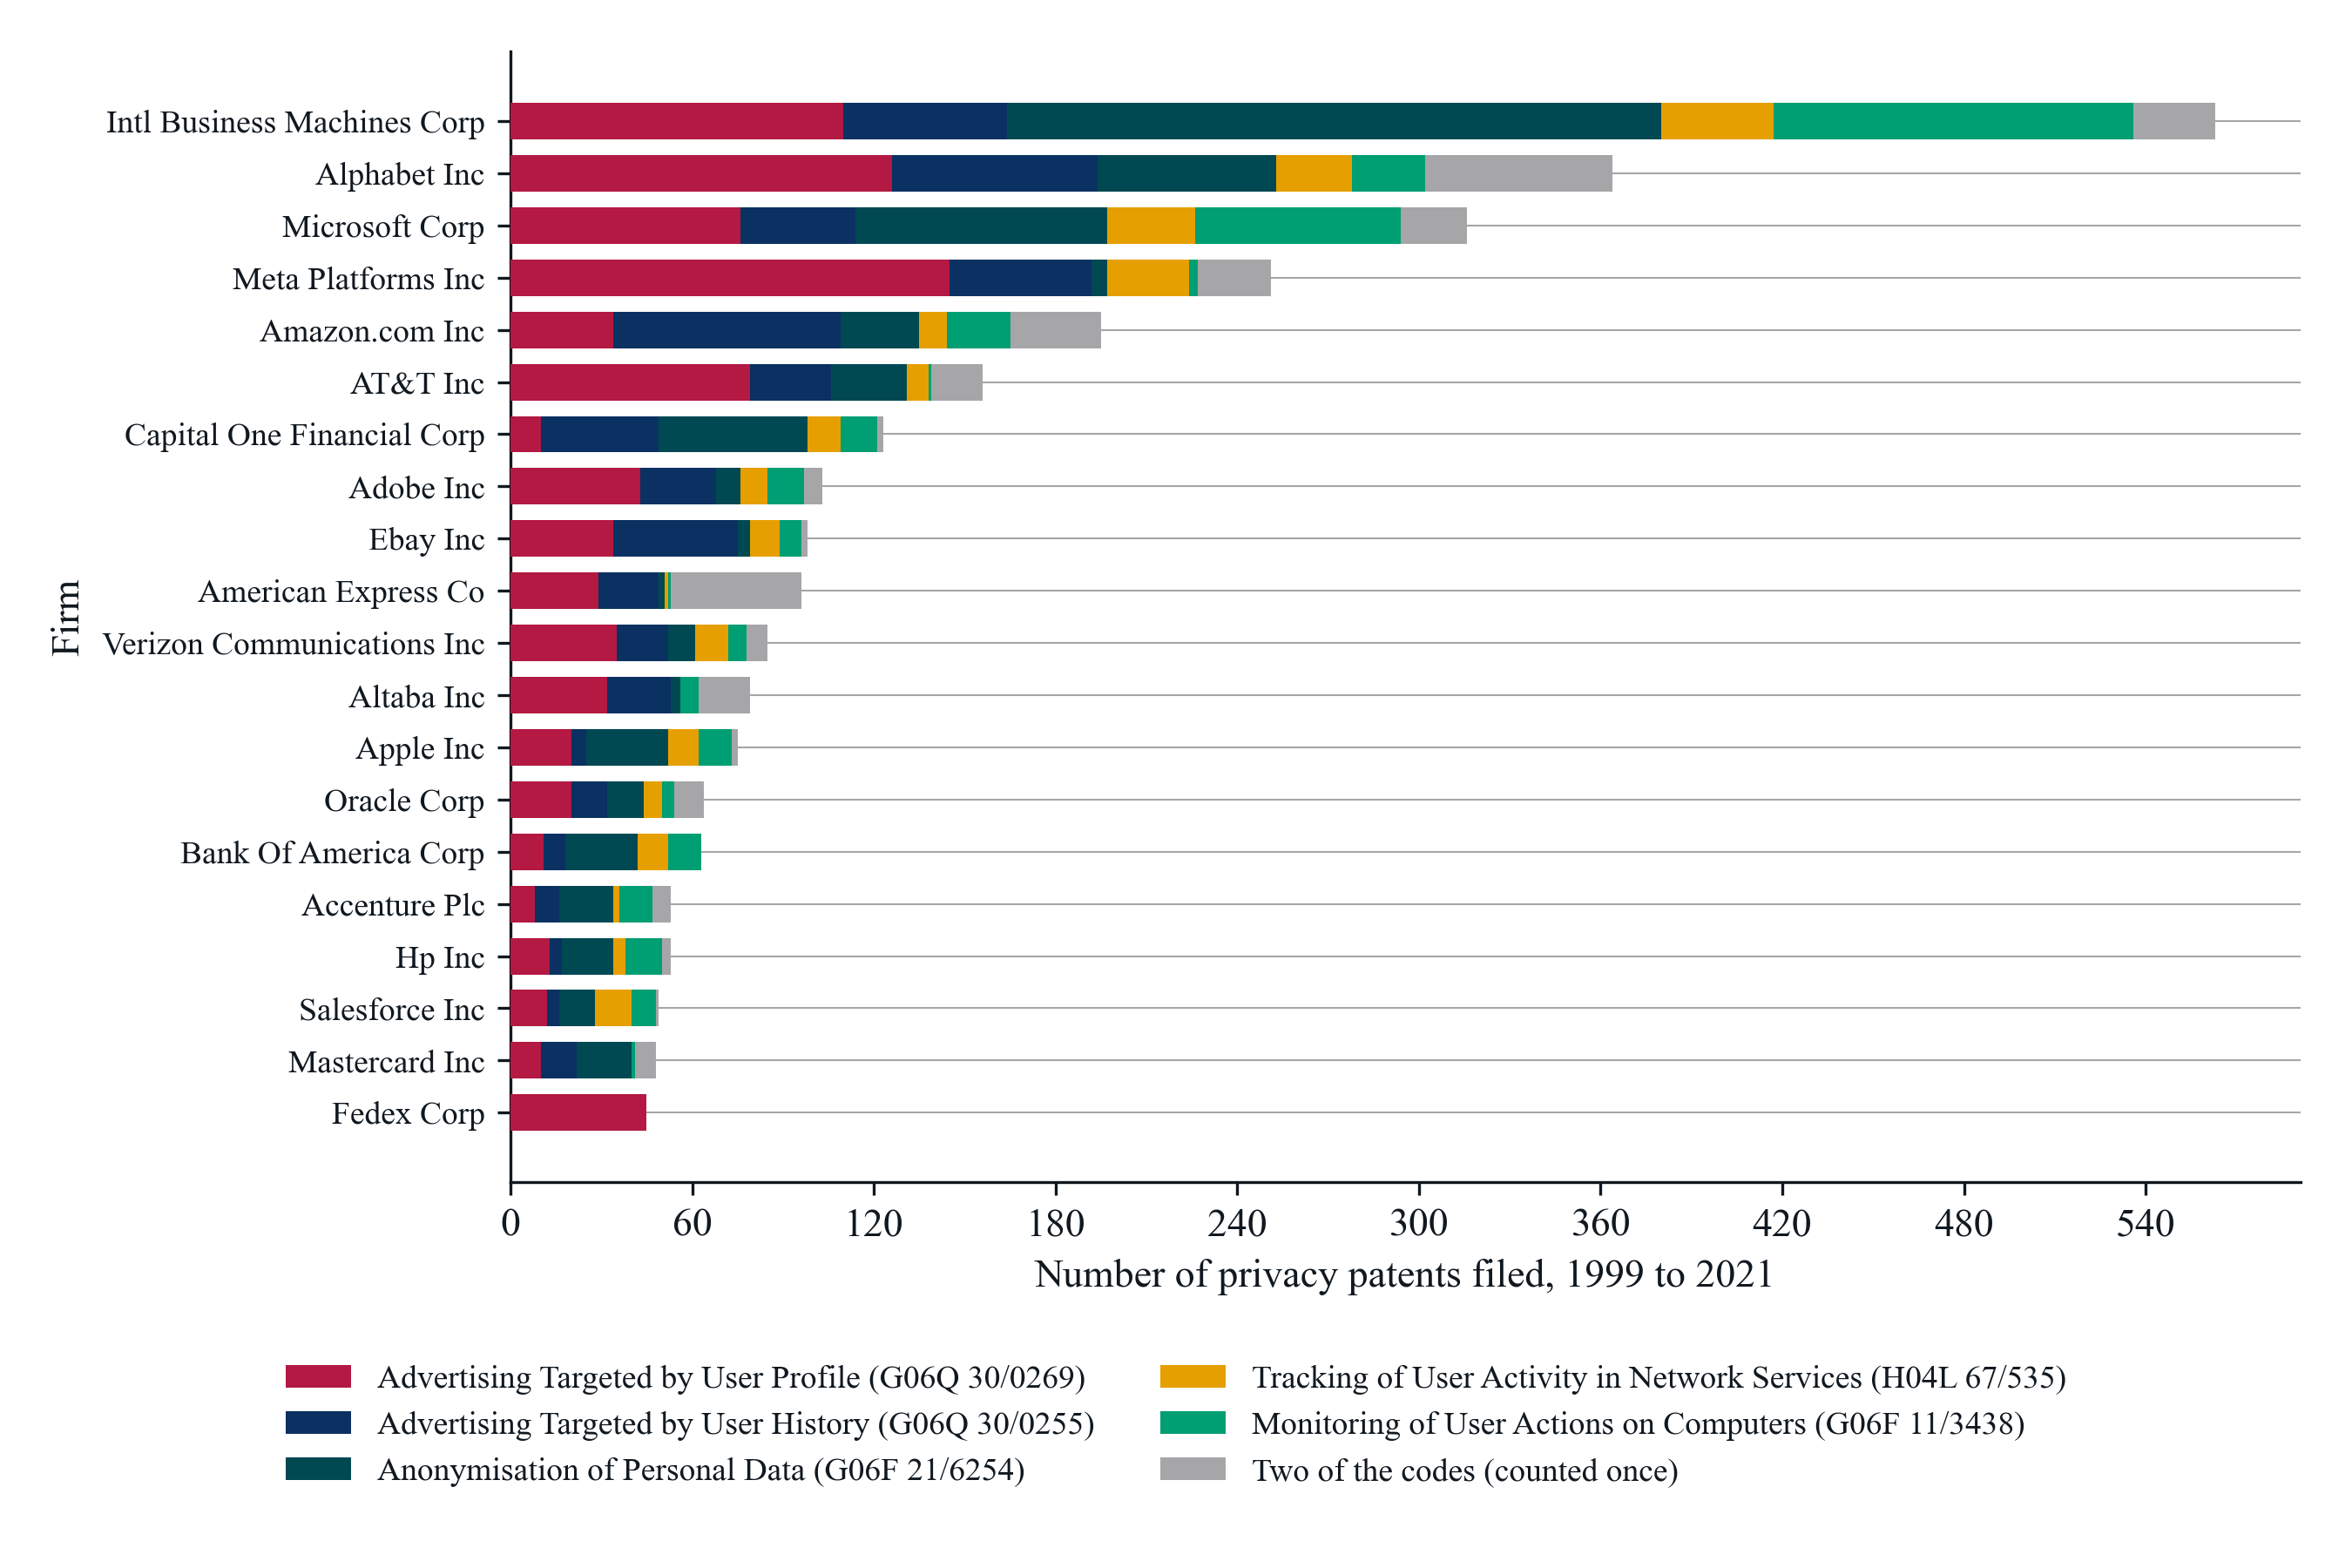

*Notes*: Each bar is one of the 20 sample firms with the most privacy patents, the largest at the top; its length is the firm's number of distinct KPSS patents filed in 1999 to 2021 that carry at least one of the five codes, as in Table 1. The bar is split into the patents that carry exactly one of the codes, colored by that code as the legend shows, and the patents that carry two of the codes, in grey, so that the segments add up to the firm's total and no patent is counted twice; across all filing firms, 361 of the 3,707 privacy patents carry two codes, and Table 1 counts such a patent under each of its codes. The codes and their definitions from the list: G06Q 30/0269, based on user profile or attribute; G06Q 30/0255, based on user history; G06F 21/6254, by anonymising data, e.g. decorrelating personal data from the owner's identification; H04L 67/535, Tracking the activity of the user (network monitoring arrangements H04L 43/00; recording of computer activity G06F 11/34); G06F 11/3438, monitoring of user actions (tracking the activity of the user H04L 67/535). A privacy patent is a KPSS patent filed by a sample firm in 1999 to 2021 that carries at least one of the 5 CPC codes of the project's privacy code list (an exact match of the full code; a listed parent code does not pull in unlisted child codes). Firm names are Compustat names in title case. The sample firms are the 1,058 firms of the all-years T3 sample (every firm with a 10-K in the sample, fiscal 1999 to 2025), linked to their KPSS patents in T4.1.1.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list in privacy_cpc/privacy_cpc_codes_MM_102926.xlsx; sample firms from the 10-K sample of T3 (SEC EDGAR); authors' calculations.

Saved PNG, SVG, and PDF: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/output/T4.2.6/fig_7_top_firms_stacked_by_code; data in fig_7_stacked_counts.csv


In [17]:
figure_name = "fig_7_top_firms_stacked_by_code"
figure_title = f"Figure 7. Privacy Patents of the {TOP_N_FIRMS} Sample Firms With the Most, Split by CPC Code, {PERIOD_WORDS}"
TWO_CODES_LABEL = "Two of the codes"
SEGMENT_ORDER = CODE_ORDER + [TWO_CODES_LABEL]
SEGMENT_COLORS = [RED, BLUE, MIDNIGHT_BLUE, "#E69F00", "#009E73", GREY]
SEGMENT_LABELS = [f"{CODE_NAMES[c][0]} ({c})" for c in CODE_ORDER] + [f"{TWO_CODES_LABEL} (counted once)"]

codes_per_patent = matches.groupby("patent_num")["cpc_display"].nunique()
segments = matches.assign(n_codes=matches["patent_num"].map(codes_per_patent))
segments["segment"] = segments["cpc_display"].where(segments["n_codes"].eq(1), TWO_CODES_LABEL)
segments = segments.drop_duplicates(["patent_num", "segment"])
assert not segments["patent_num"].duplicated().any(), "a patent must fall in exactly one segment"
stack = segments.pivot_table(index="gvkey", columns="segment", values="patent_num", aggfunc="nunique", fill_value=0)
stack = stack.reindex(columns=SEGMENT_ORDER, fill_value=0)
top_firms = by_firm_code.head(TOP_N_FIRMS)
stack = stack.reindex(top_firms["gvkey"]).fillna(0).astype(int)
assert (stack.sum(axis=1).to_numpy() == top_firms["n_privacy_patents"].to_numpy()).all(), "segments must add up to the firm's distinct privacy patents"
n_two_codes_all = int(segments["segment"].eq(TWO_CODES_LABEL).sum())
stack_out = stack.copy()
stack_out.insert(0, "firm", top_firms["conm"].map(title_case_name).to_numpy())
stack_out.to_csv(OUTPUT_FOLDER / "fig_7_stacked_counts.csv")

figure, axis = plt.subplots()
figure.subplots_adjust(left=0.30, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.26)
firm_names = top_firms["conm"].map(title_case_name).to_numpy()[::-1]
stack_plot = stack.iloc[::-1]
left_edge = pd.Series(0, index=stack_plot.index)
for segment, color, label in zip(SEGMENT_ORDER, SEGMENT_COLORS, SEGMENT_LABELS):
    axis.barh(firm_names, stack_plot[segment].to_numpy(), left=left_edge.to_numpy(), color=color, height=0.7, label=label, zorder=3)
    left_edge = left_edge + stack_plot[segment]
axis.set_xlabel(f"Number of privacy patents filed, {PERIOD_WORDS}")
axis.set_ylabel("Firm")
axis.set_xlim(0, top_firms["n_privacy_patents"].max() * 1.05)
axis.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
axis.tick_params(axis="y", labelsize=9)
axis.spines[["top", "right"]].set_visible(False)
legend = figure.legend(loc="lower center", ncol=2, frameon=False, fontsize=9, bbox_to_anchor=(0.5, MARGIN_INCHES / FIGURE_HEIGHT), bbox_transform=figure.transFigure)

figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
legend_top = legend.get_window_extent(renderer).y1
bottom_shift = (legend_top + margin_pixels - axis.xaxis.label.get_window_extent(renderer).y0) / figure.bbox.height
figure.subplots_adjust(left=figure.subplotpars.left + left_shift, bottom=figure.subplotpars.bottom + bottom_shift)
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

figure_notes = (f"Each bar is one of the {TOP_N_FIRMS} sample firms with the most privacy patents, the largest at the top; its length is the firm's number of distinct KPSS patents filed in {PERIOD_WORDS} "
                f"that carry at least one of the five codes, as in Table 1. The bar is split into the patents that carry exactly one of the codes, colored by that code as the legend shows, "
                f"and the patents that carry two of the codes, in grey, so that the segments add up to the firm's total and no patent is counted twice; across all filing firms, "
                f"{n_two_codes_all:,} of the {N_PRIVACY_PATENTS:,} privacy patents carry two codes, and Table 1 counts such a patent under each of its codes. "
                f"The codes and their definitions from the list: {CODE_DEFINITIONS}. {PRIVACY_WORDS}. Firm names are Compustat names in title case. The sample firms are {SAMPLE_WORDS}.")
display(Markdown(f"**{figure_title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {figure_notes}\n\n*Source*: {SOURCE}"))
print(f"Saved PNG, SVG, and PDF: {OUTPUT_FOLDER / figure_name}; data in fig_7_stacked_counts.csv")
